<a href="https://colab.research.google.com/github/predowss/passo-firme-visao/blob/main/notebooks/01_treino_yolo26_colab.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Passo Firme — treino do detector de barreiras de calçada (YOLO26)

Disciplina **Applied Computer Vision** · Global Solution 2026.2 · CitizenTech

Este notebook treina um YOLO26 sob medida para achar `buraco`, `desnivel` e `obstaculo` (e, se houver exemplos suficientes, `veiculo_na_calcada`) em fotos de calçadas de São Paulo, avalia o resultado e gera as figuras do relatório.

**Antes de rodar**
1. *Ambiente de execução → Alterar o tipo de ambiente de execução →* **GPU T4**.
2. Clique no ícone de chave (**Secrets**) na barra lateral, crie `ROBOFLOW_API_KEY` com a chave do Roboflow (*Settings → API Keys*) e libere o acesso deste notebook. A chave nunca fica escrita no código.
3. Confira `WORKSPACE`, `PROJETO` e `VERSAO` na seção 1 (já vêm preenchidos para o projeto do grupo).
4. *Ambiente de execução →* **Executar tudo**. Leva cerca de 40 minutos; deixem a aba aberta. No fim, o navegador baixa o `best.pt` e um zip com os resultados.

**Ao terminar:** *Arquivo → Salvar uma cópia no GitHub* (pasta `notebooks/` do repositório), com as saídas. O professor precisa ver os resultados sem rodar nada.

In [1]:
!nvidia-smi

Mon Nov 16 00:00:10 2026       
+-----------------------------------------------------------------------------------------+
| NVIDIA-SMI 580.82.07              Driver Version: 580.82.07      CUDA Version: 13.0     |
+-----------------------------------------+------------------------+----------------------+
| GPU  Name                 Persistence-M | Bus-Id          Disp.A | Volatile Uncorr. ECC |
| Fan  Temp   Perf          Pwr:Usage/Cap |           Memory-Usage | GPU-Util  Compute M. |
|                                         |                        |               MIG M. |
|=========================================+========================+======================|
|   0  Tesla T4                       Off |   00000000:00:04.0 Off |                    0 |
| N/A   39C    P8             11W /   70W |       0MiB /  15360MiB |      0%      Default |
|                                         |                        |                  N/A |
+-----------------------------------------+-----

In [2]:
%pip install -q "ultralytics>=8.4.0" roboflow
import ultralytics
ultralytics.checks()

Ultralytics 8.4.214 🚀 Python-3.13.16 torch-2.14.1+cu130 CUDA:0 (Tesla T4, 14913MiB)
Setup complete ✅ (2 CPUs, 12.7 GB RAM, 0.1/112.6 GB disk)


## 1. Baixar o dataset do Roboflow

A versão usada aqui junta as imagens de calçadas de São Paulo baixadas do Mapillary (arquivos `sp_<bairro>_<id>.jpg`, anotadas pelo grupo) e as 105 imagens clonadas do dataset aberto *Sidewalk obstacles* (Blindspot), com as classes de origem reagrupadas em `obstaculo` pelo *Modify Classes*. O teste tem só imagens de SP. O formato `yolov8` é o mesmo `.txt` que o YOLO26 lê.

In [3]:
from google.colab import userdata
from roboflow import Roboflow

WORKSPACE = "pedros-workspace-md4aw"   # aparece na URL: app.roboflow.com/<workspace>/<projeto>
PROJETO = "passo-firme-calcadas"   # nome do projeto no Roboflow
VERSAO = 1                         # número da versão gerada em Versions (imagens de SP + Blindspot)

rf = Roboflow(api_key=userdata.get("ROBOFLOW_API_KEY"))
dataset = rf.workspace(WORKSPACE).project(PROJETO).version(VERSAO).download("yolov8", location="/content/dataset", overwrite=True)

loading Roboflow workspace...
loading Roboflow project...



Extracting Dataset Version Zip to /content/dataset in yolov8:: 100%|██████████| 575/575 [00:00<00:00, 1266.15it/s]


In [4]:
import yaml
from pathlib import Path

def preparar_yaml(pasta):
    """O data.yaml exportado às vezes traz caminhos relativos que quebram no Colab: fixamos os absolutos."""
    arquivo = Path(pasta) / "data.yaml"
    cfg = yaml.safe_load(arquivo.read_text())
    cfg["path"] = str(pasta)
    cfg["train"], cfg["val"] = "train/images", "valid/images"
    if (Path(pasta) / "test" / "images").exists():
        cfg["test"] = "test/images"
    else:
        cfg.pop("test", None)
    arquivo.write_text(yaml.safe_dump(cfg, allow_unicode=True))
    return str(arquivo), cfg

DATA, cfg = preparar_yaml(dataset.location)
SPLIT = "test" if "test" in cfg else "val"          # conjunto usado na avaliação final
PASTA_TESTE = "test" if SPLIT == "test" else "valid"
NOMES = cfg["names"] if isinstance(cfg["names"], list) else [cfg["names"][k] for k in sorted(cfg["names"])]
print("Classes:", NOMES, "| avaliação final em:", SPLIT)

Classes: ['buraco', 'desnivel', 'obstaculo'] | avaliação final em: test


In [5]:
import pandas as pd
from collections import Counter

linhas = []
for rotulo_conjunto, pasta in [("treino", "train"), ("validação", "valid"), ("teste", "test")]:
    base = Path(dataset.location) / pasta
    if not base.exists():
        continue
    contagem, nulas = Counter(), 0
    imagens = [p for p in (base / "images").glob("*") if p.suffix.lower() in {".jpg", ".jpeg", ".png"}]
    for img in imagens:
        rot = base / "labels" / (img.stem + ".txt")
        anot = [l for l in rot.read_text().splitlines() if l.strip()] if rot.exists() else []
        nulas += not anot
        for l in anot:
            contagem[int(float(l.split()[0]))] += 1
    linhas.append({"conjunto": rotulo_conjunto, "imagens": len(imagens), "sem barreira": nulas,
                   **{n: contagem.get(i, 0) for i, n in enumerate(NOMES)}})

tabela_dataset = pd.DataFrame(linhas)
tabela_dataset   # vai para o PDF (seção Metodologia)

,conjunto,imagens,sem barreira,buraco,desnivel,obstaculo
0,treino,216,21,58,52,463
1,validação,38,1,5,17,90
2,teste,31,5,25,10,36


## 2. Treino-relâmpago (só para testar o caminho)

Dez épocas confirmam que dados, classes e caminhos estão certos antes de gastar tempo de GPU. **Não use estes números no relatório.**

In [6]:
from ultralytics import YOLO

YOLO("yolo26n.pt").train(data=DATA, epochs=10, imgsz=640, batch=16,
                         project="/content/runs", name="00_relampago", exist_ok=True)

Ultralytics 8.4.214 🚀 Python-3.13.16 torch-2.14.1+cu130 CUDA:0 (Tesla T4, 14913MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=16, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/content/dataset/data.yaml, degrees=0.0, deterministic=True, device=, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=10, erasing=0.4, exist_ok=True, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=640, iou=None, kobj=1.0, line_width=None, lr0=0.01, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=yolo26n.pt, momentum=0.937, mosaic=1.0, multi_scale=0.0, name=00_relampago, nbs=64, nms=None, opset=None, optimize=False, opt

ultralytics.utils.metrics.DetMetrics object with attributes:

ap_class_index: array([0, 1, 2])
box: ultralytics.utils.metrics.Metric object
confusion_matrix: <ultralytics.utils.metrics.ConfusionMatrix object at 0x7995284b8230>
curves: ['Precision-Recall(B)', 'F1-Confidence(B)', 'Precision-Confidence(B)', 'Recall-Confidence(B)']
curves_results: [[array([          0,    0.001001,    0.002002,    0.003003,    0.004004,    0.005005,    0.006006,    0.007007,    0.008008,    0.009009,     0.01001,    0.011011,    0.012012,    0.013013,    0.014014,    0.015015,    0.016016,    0.017017,    0.018018,    0.019019,     0.02002,    0.021021,    0.022022,    0.023023,
          0.024024,    0.025025,    0.026026,    0.027027,    0.028028,    0.029029,     0.03003,    0.031031,    0.032032,    0.033033,    0.034034,    0.035035,    0.036036,    0.037037,    0.038038,    0.039039,     0.04004,    0.041041,    0.042042,    0.043043,    0.044044,    0.045045,    0.046046,    0.047047,
          0.04

## 3. Experimentos A e A2 — YOLO26n em 640 e em 960 pixels

Ajuste fino (*transfer learning*) a partir dos pesos pré-treinados no COCO, com o mesmo modelo em duas resoluções. O primeiro treino (640) mostrou que `buraco` e `desnivel` quase não eram aprendidos: as imagens de SP têm 1920 px de largura e, reduzidas a 640, um buraco de 60 px vira 20 px. O A2 testa se uma resolução maior resolve.

| Parâmetro | Valor |
| --- | --- |
| Modelo base | `yolo26n.pt` (COCO) |
| Tamanho da imagem | 640 (A) e 960 (A2) |
| Épocas | até 80, com parada antecipada após 20 sem melhora (`patience`) |
| Lote | 16 |
| Semente | 42 |
| Aumento de dados | padrão do Ultralytics: mosaico, variação de cor (HSV), escala, translação e espelhamento horizontal. Sem espelhamento vertical: a calçada nunca aparece de cabeça para baixo. |

In [7]:
EPOCAS = 80
comum = dict(data=DATA, epochs=EPOCAS, patience=20, batch=16, seed=42,
             project="/content/runs", exist_ok=True, plots=True)

YOLO("yolo26n.pt").train(name="A_yolo26n", imgsz=640, **comum)
A_BEST = "/content/runs/A_yolo26n/weights/best.pt"

Ultralytics 8.4.214 🚀 Python-3.13.16 torch-2.14.1+cu130 CUDA:0 (Tesla T4, 14913MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=16, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/content/dataset/data.yaml, degrees=0.0, deterministic=True, device=, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=80, erasing=0.4, exist_ok=True, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=640, iou=None, kobj=1.0, line_width=None, lr0=0.01, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=yolo26n.pt, momentum=0.937, mosaic=1.0, multi_scale=0.0, name=A_yolo26n, nbs=64, nms=None, opset=None, optimize=False, optimi

In [8]:
YOLO("yolo26n.pt").train(name="A2_yolo26n_960", imgsz=960, **comum)
A2_BEST = "/content/runs/A2_yolo26n_960/weights/best.pt"

Ultralytics 8.4.214 🚀 Python-3.13.16 torch-2.14.1+cu130 CUDA:0 (Tesla T4, 14913MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=16, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/content/dataset/data.yaml, degrees=0.0, deterministic=True, device=, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=80, erasing=0.4, exist_ok=True, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=960, iou=None, kobj=1.0, line_width=None, lr0=0.01, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=yolo26n.pt, momentum=0.937, mosaic=1.0, multi_scale=0.0, name=A2_yolo26n_960, nbs=64, nms=None, opset=None, optimize=False, o

A_yolo26n


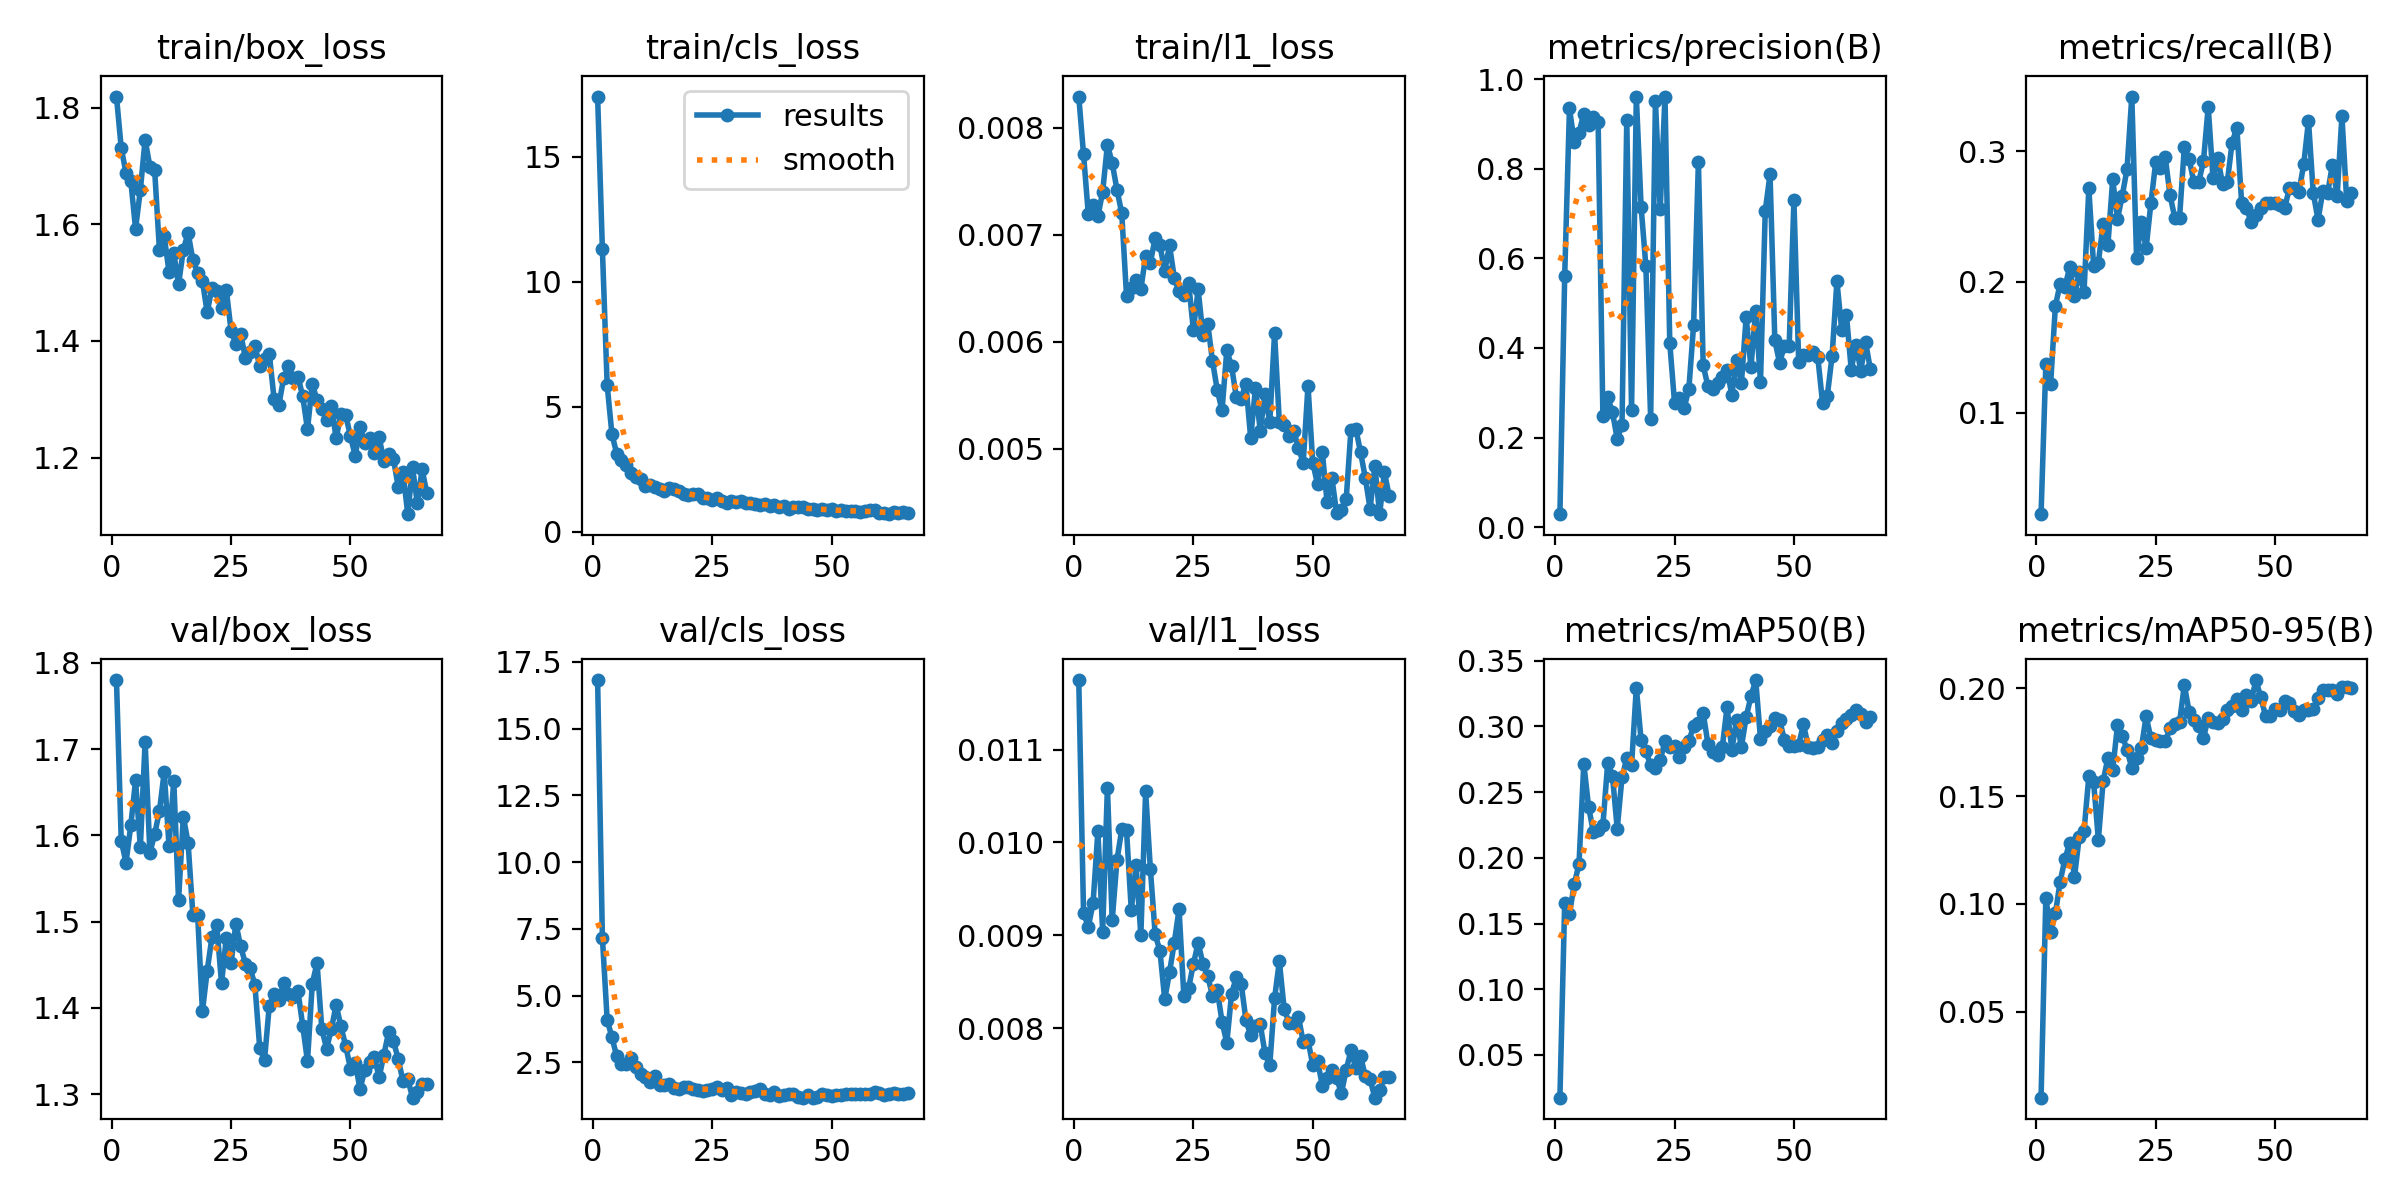

A2_yolo26n_960


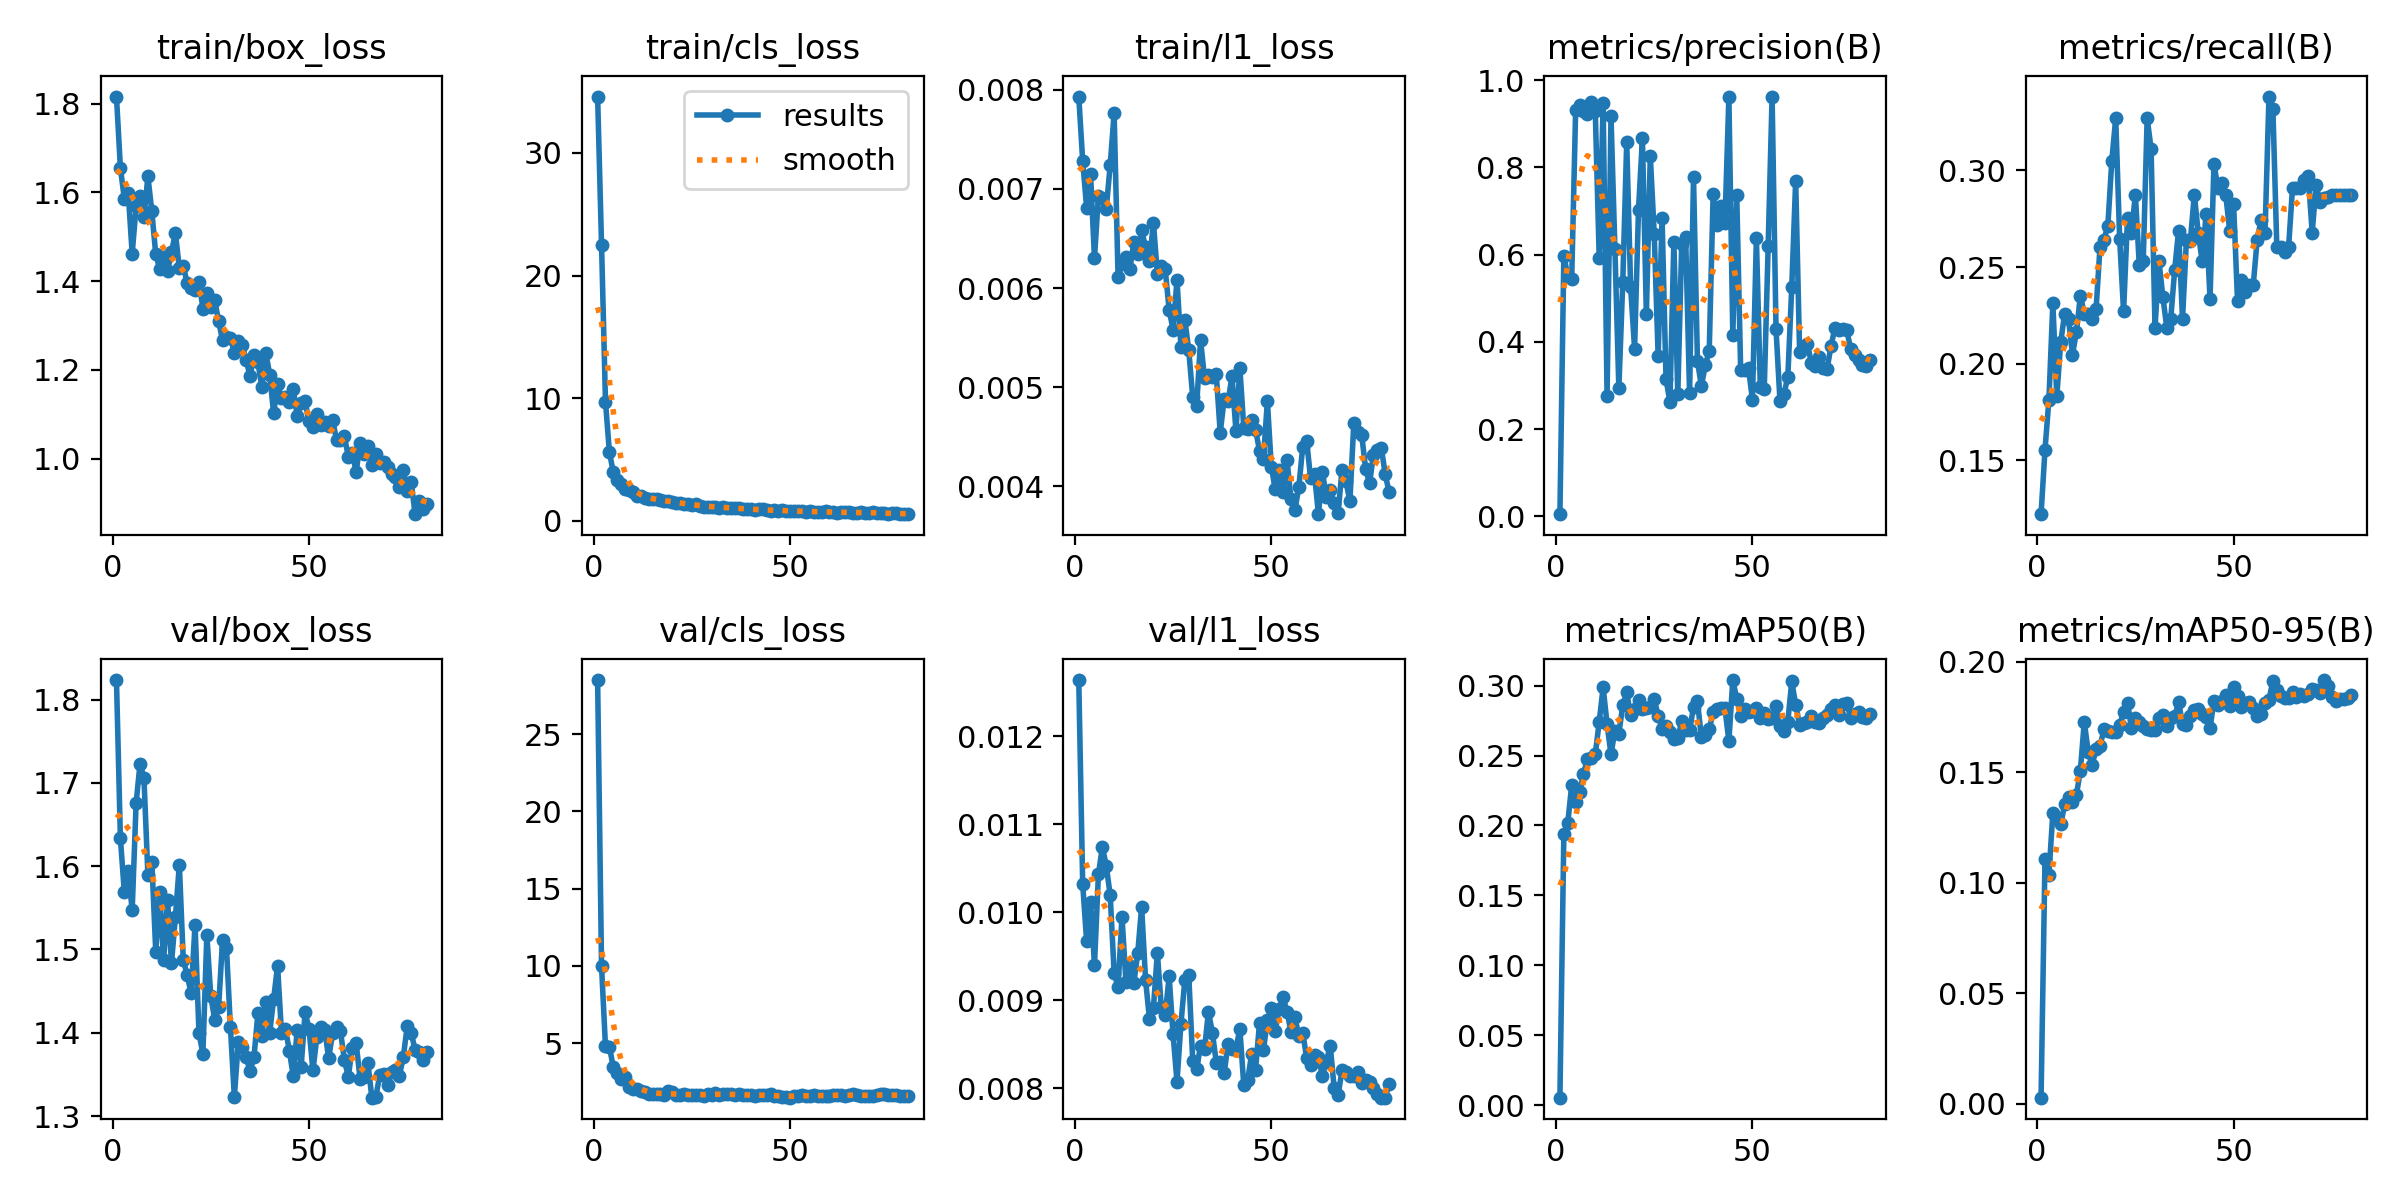

In [9]:
from IPython.display import Image, display
for nome in ["A_yolo26n", "A2_yolo26n_960"]:   # curvas de perda e métricas por época
    print(nome)
    display(Image(f"/content/runs/{nome}/results.png", width=950))

## 4. Avaliação e escolha do modelo

O modelo é **escolhido pela validação** (mAP50; empate decidido pelo recall) e só depois medido no **teste**, com fotos de ruas que nenhum dos dois viu. Escolher pelo teste inflaria o resultado.

- **Precisão:** das caixas que o modelo desenhou, quantas estavam certas.
- **Recall:** das barreiras que existiam, quantas o modelo achou. Para quem anda com bengala ou cadeira de rodas, um buraco não detectado custa mais que um falso alarme.
- **mAP50:** média, entre as classes, da área sob a curva precisão × recall, contando como acerto a caixa com IoU ≥ 0,5.
- **mAP50-95:** a mesma média, exigindo caixas cada vez mais justas (IoU de 0,5 a 0,95).

In [10]:
def avaliar(pesos, nome, imgsz, split=SPLIT):
    m = YOLO(pesos).val(data=DATA, split=split, imgsz=imgsz, batch=16,
                        project="/content/runs", name=nome, exist_ok=True)
    por_classe = []
    for i, c in enumerate(m.box.ap_class_index):
        p, r, ap50, ap = m.box.class_result(i)
        por_classe.append({"classe": m.names[int(c)], "precisão": p, "recall": r, "mAP50": ap50, "mAP50-95": ap})
    geral = {"precisão": m.box.mp, "recall": m.box.mr, "mAP50": m.box.map50, "mAP50-95": m.box.map,
             "ms por imagem (GPU T4)": m.speed["inference"]}
    return pd.DataFrame(por_classe).round(3), geral

# 1) escolha pela validação
_, valA = avaliar(A_BEST, "A_valid", 640, split="val")
_, valA2 = avaliar(A2_BEST, "A2_valid", 960, split="val")
candidatos = {"A (640)": (A_BEST, 640, valA), "A2 (960)": (A2_BEST, 960, valA2)}
ESCOLHIDO = max(candidatos, key=lambda k: (candidatos[k][2]["mAP50"], candidatos[k][2]["recall"]))
MELHOR, IMG = candidatos[ESCOLHIDO][0], candidatos[ESCOLHIDO][1]
print("Validação:", {k: round(v[2]["mAP50"], 3) for k, v in candidatos.items()}, "-> escolhido:", ESCOLHIDO)

# 2) medida final no teste
tabelaA, geralA = avaliar(A_BEST, "A_teste", 640)
tabelaA2, geralA2 = avaliar(A2_BEST, "A2_teste", 960)
resolucao = pd.DataFrame([{"modelo": "YOLO26n 640 (A)", **geralA}, {"modelo": "YOLO26n 960 (A2)", **geralA2}]).round(3)
resolucao   # vai para o PDF: efeito da resolução

Ultralytics 8.4.214 🚀 Python-3.13.16 torch-2.14.1+cu130 CUDA:0 (Tesla T4, 14913MiB)
YOLO26n summary (fused): 121 layers, 2,390,221 parameters, 0 gradients, 5.4 GFLOPs
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 2667.4±1479.6 MB/s, size: 774.5 KB)
val: Scanning /content/dataset/valid/labels.cache... 38 images, 1 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 38/38 8.9Mit/s 0.0s
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 3/3 1.7it/s 1.8s
                   all         38        112      0.417      0.252      0.306      0.204
                buraco          4          5          0          0    0.00319    0.00106
              desnivel         12         17      0.375     0.0588     0.0764     0.0435
             obstaculo         30         90      0.875      0.697      0.838      0.567
Speed: 4.4ms preprocess, 9.6ms inference, 0.0ms loss, 3.6ms postprocess per image
Results saved to /content/runs/A_valid
Ultralytics 8.4.2

,modelo,precisão,recall,mAP50,mAP50-95,ms por imagem (GPU T4)
0,YOLO26n 640 (A),0.476,0.139,0.159,0.082,7.348
1,YOLO26n 960 (A2),0.739,0.141,0.146,0.061,10.563


In [11]:
print("Teste, por classe — A (640)")
display(tabelaA)
print("Teste, por classe — A2 (960)")
display(tabelaA2)

Teste, por classe — A (640)


,classe,precisão,recall,mAP50,mAP50-95
0,buraco,0.266,0.040,0.063,0.015
1,desnivel,0.594,0.100,0.119,0.068
2,obstaculo,0.568,0.278,0.296,0.165


Teste, por classe — A2 (960)


,classe,precisão,recall,mAP50,mAP50-95
0,buraco,1.000,0.000,0.041,0.013
1,desnivel,0.645,0.200,0.151,0.035
2,obstaculo,0.572,0.222,0.247,0.135


BoxF1_curve.png


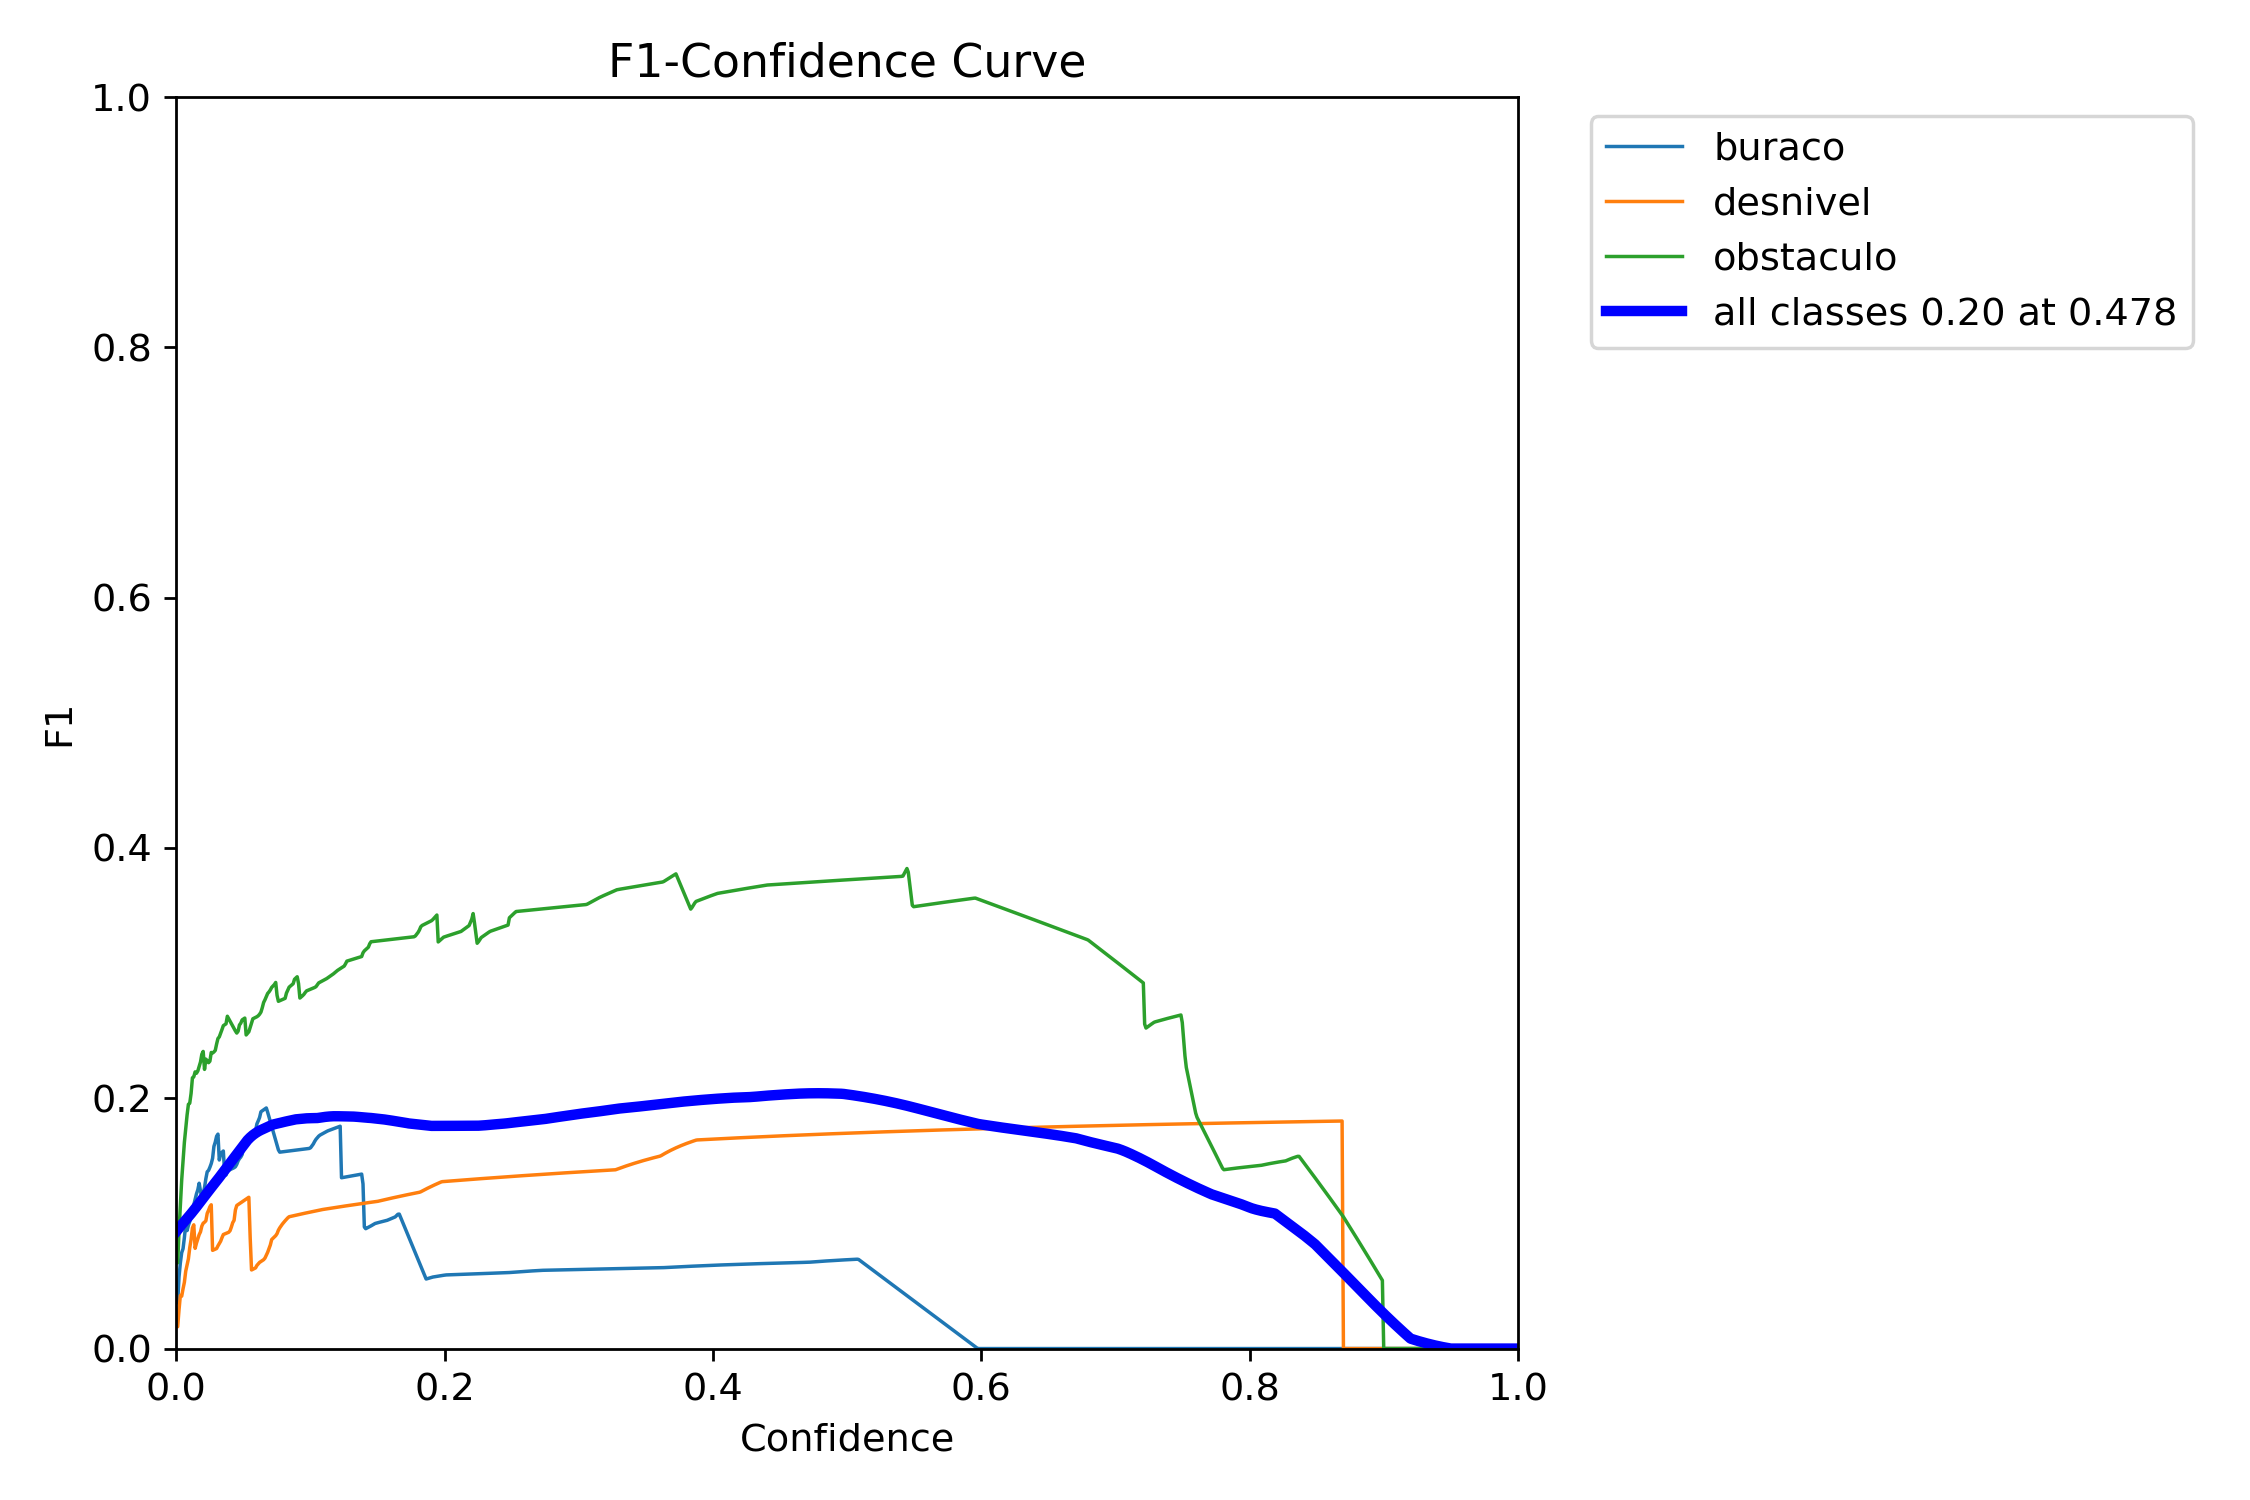

BoxPR_curve.png


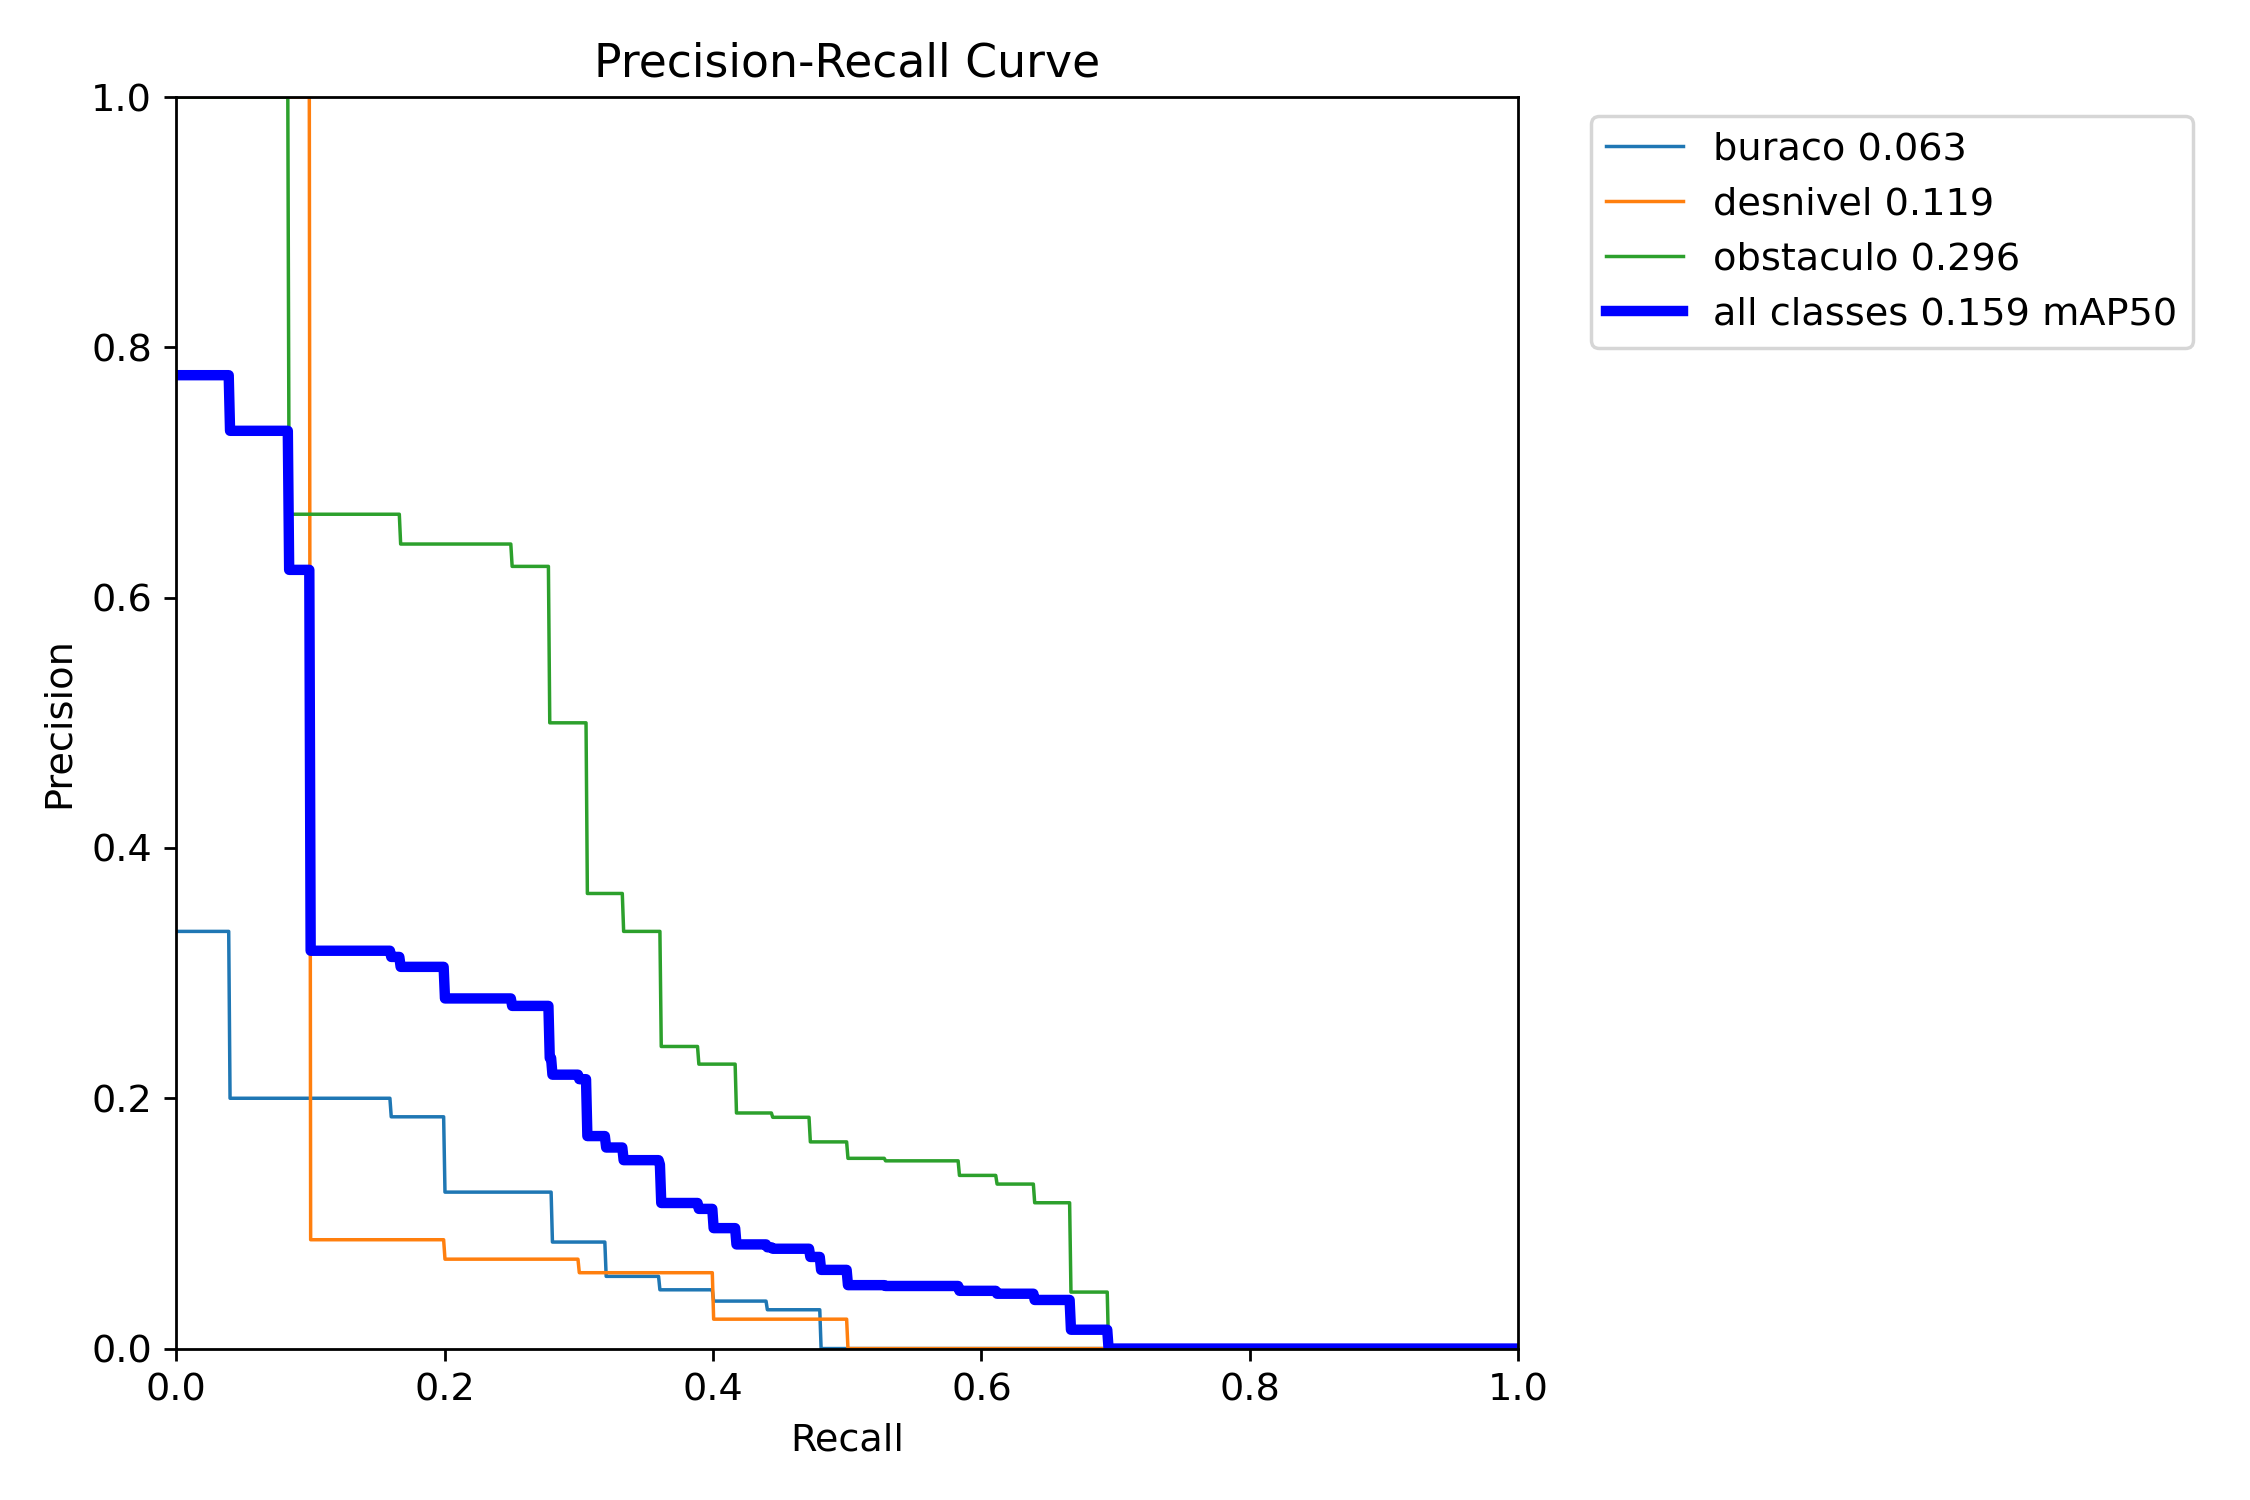

BoxP_curve.png


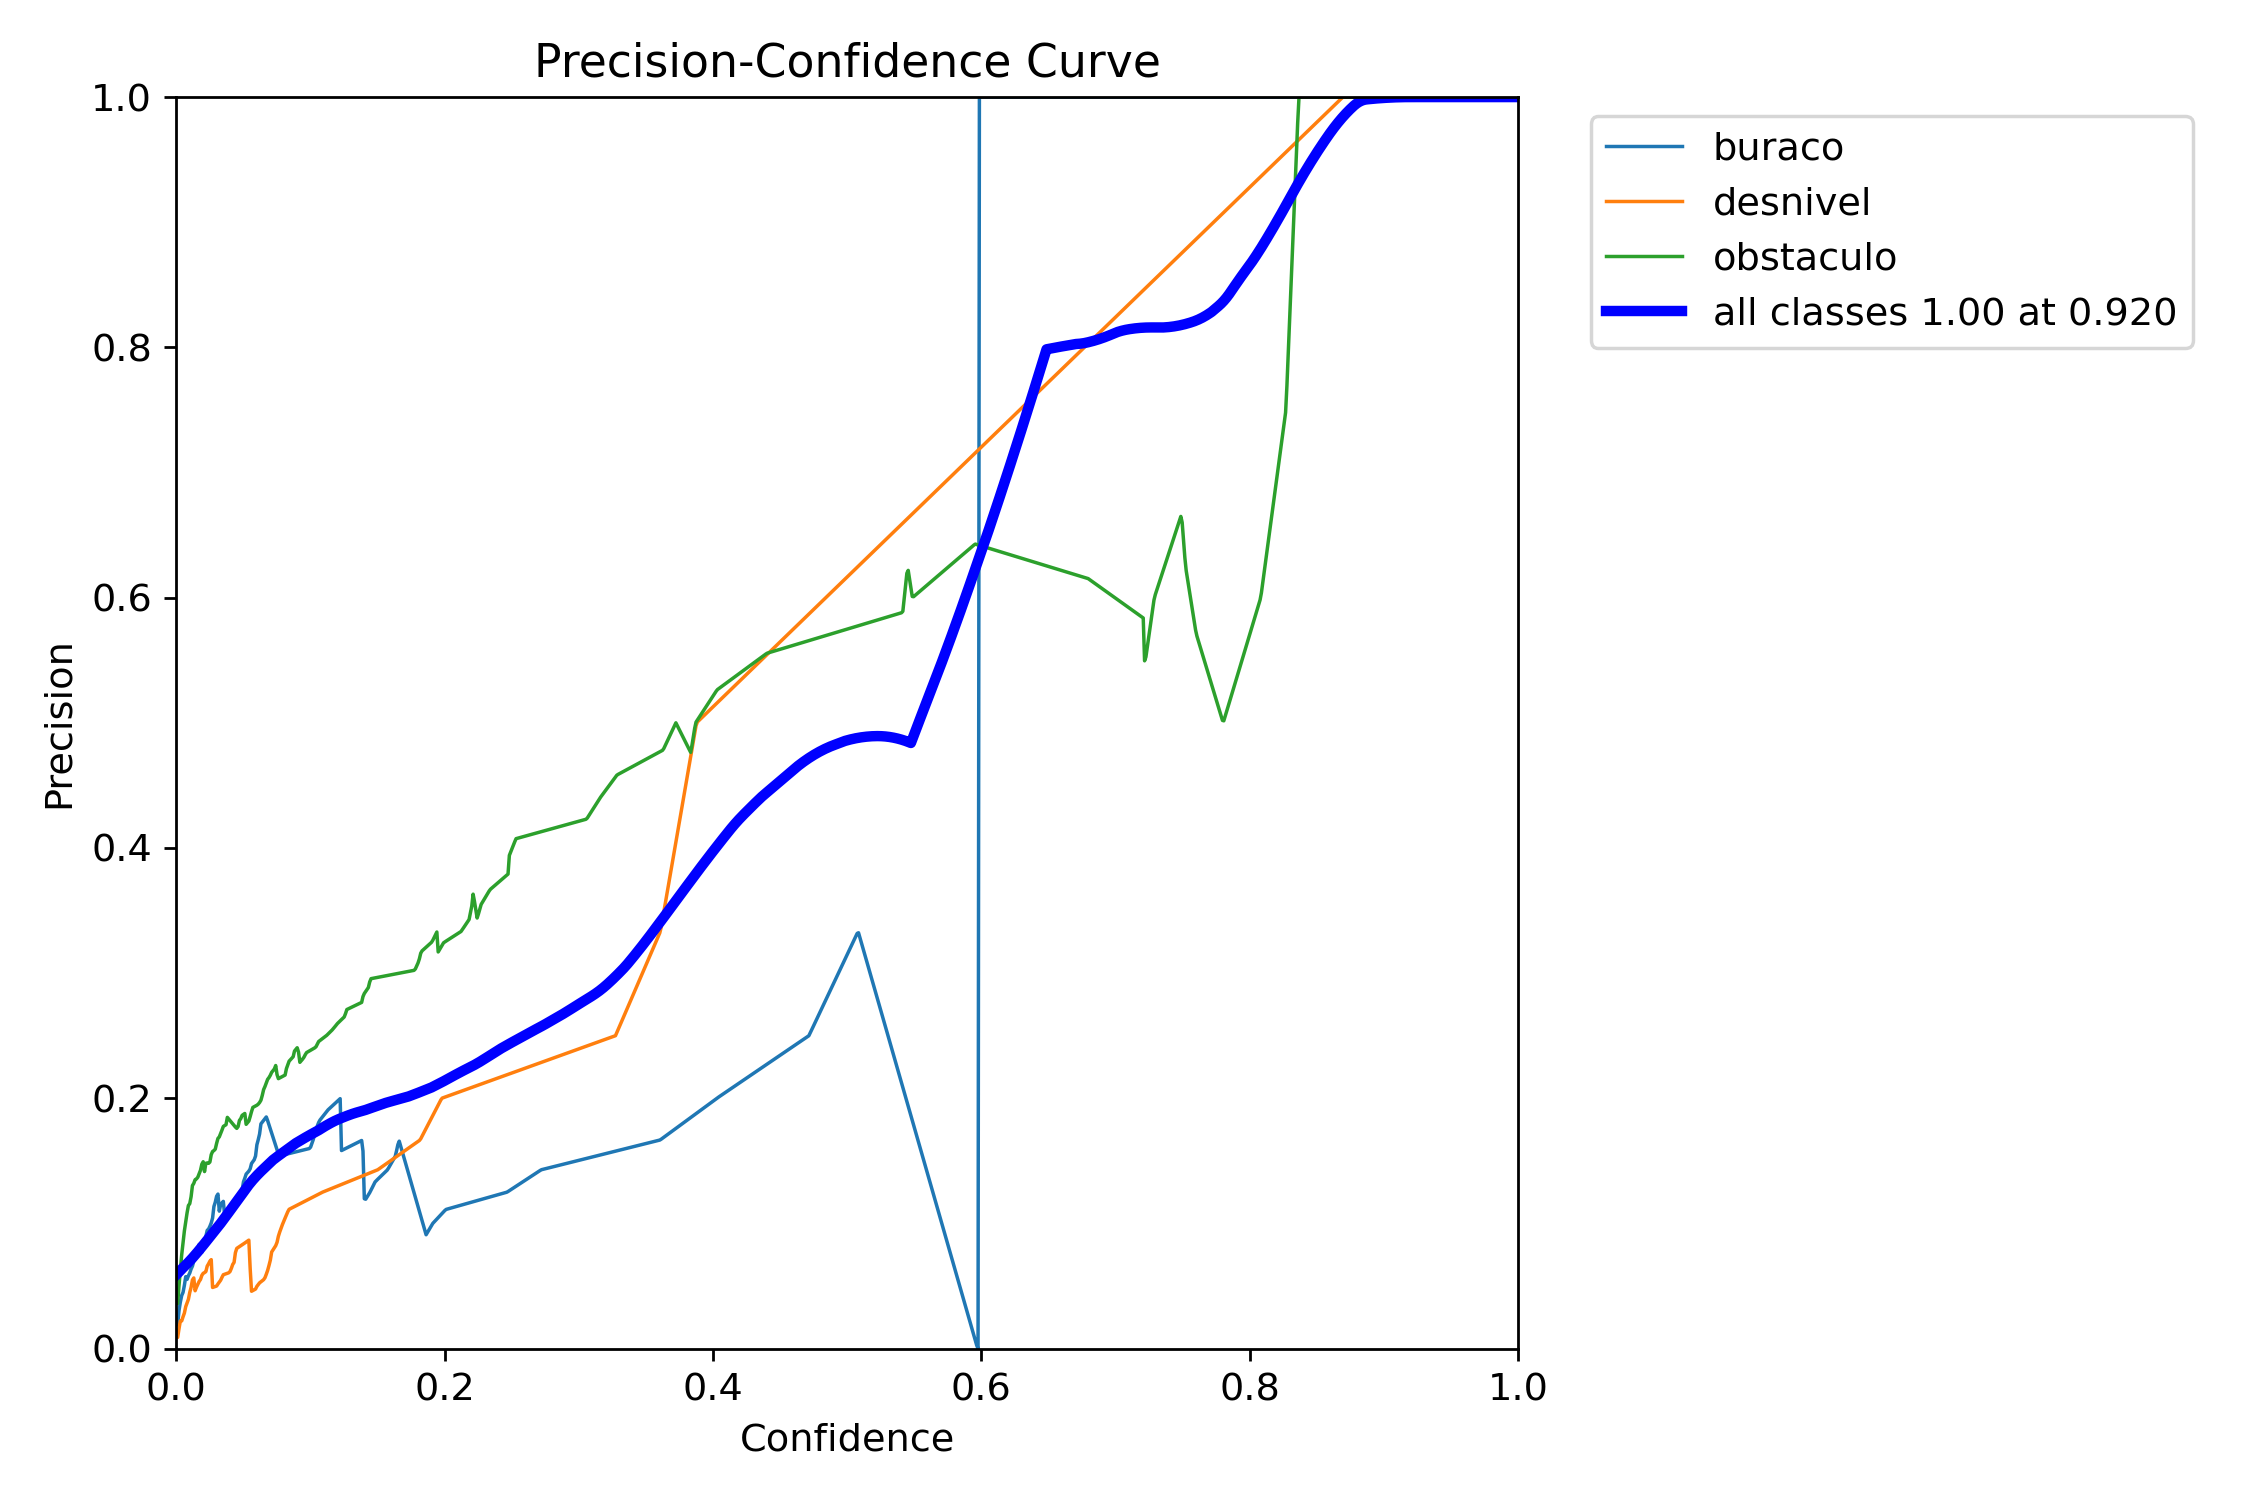

BoxR_curve.png


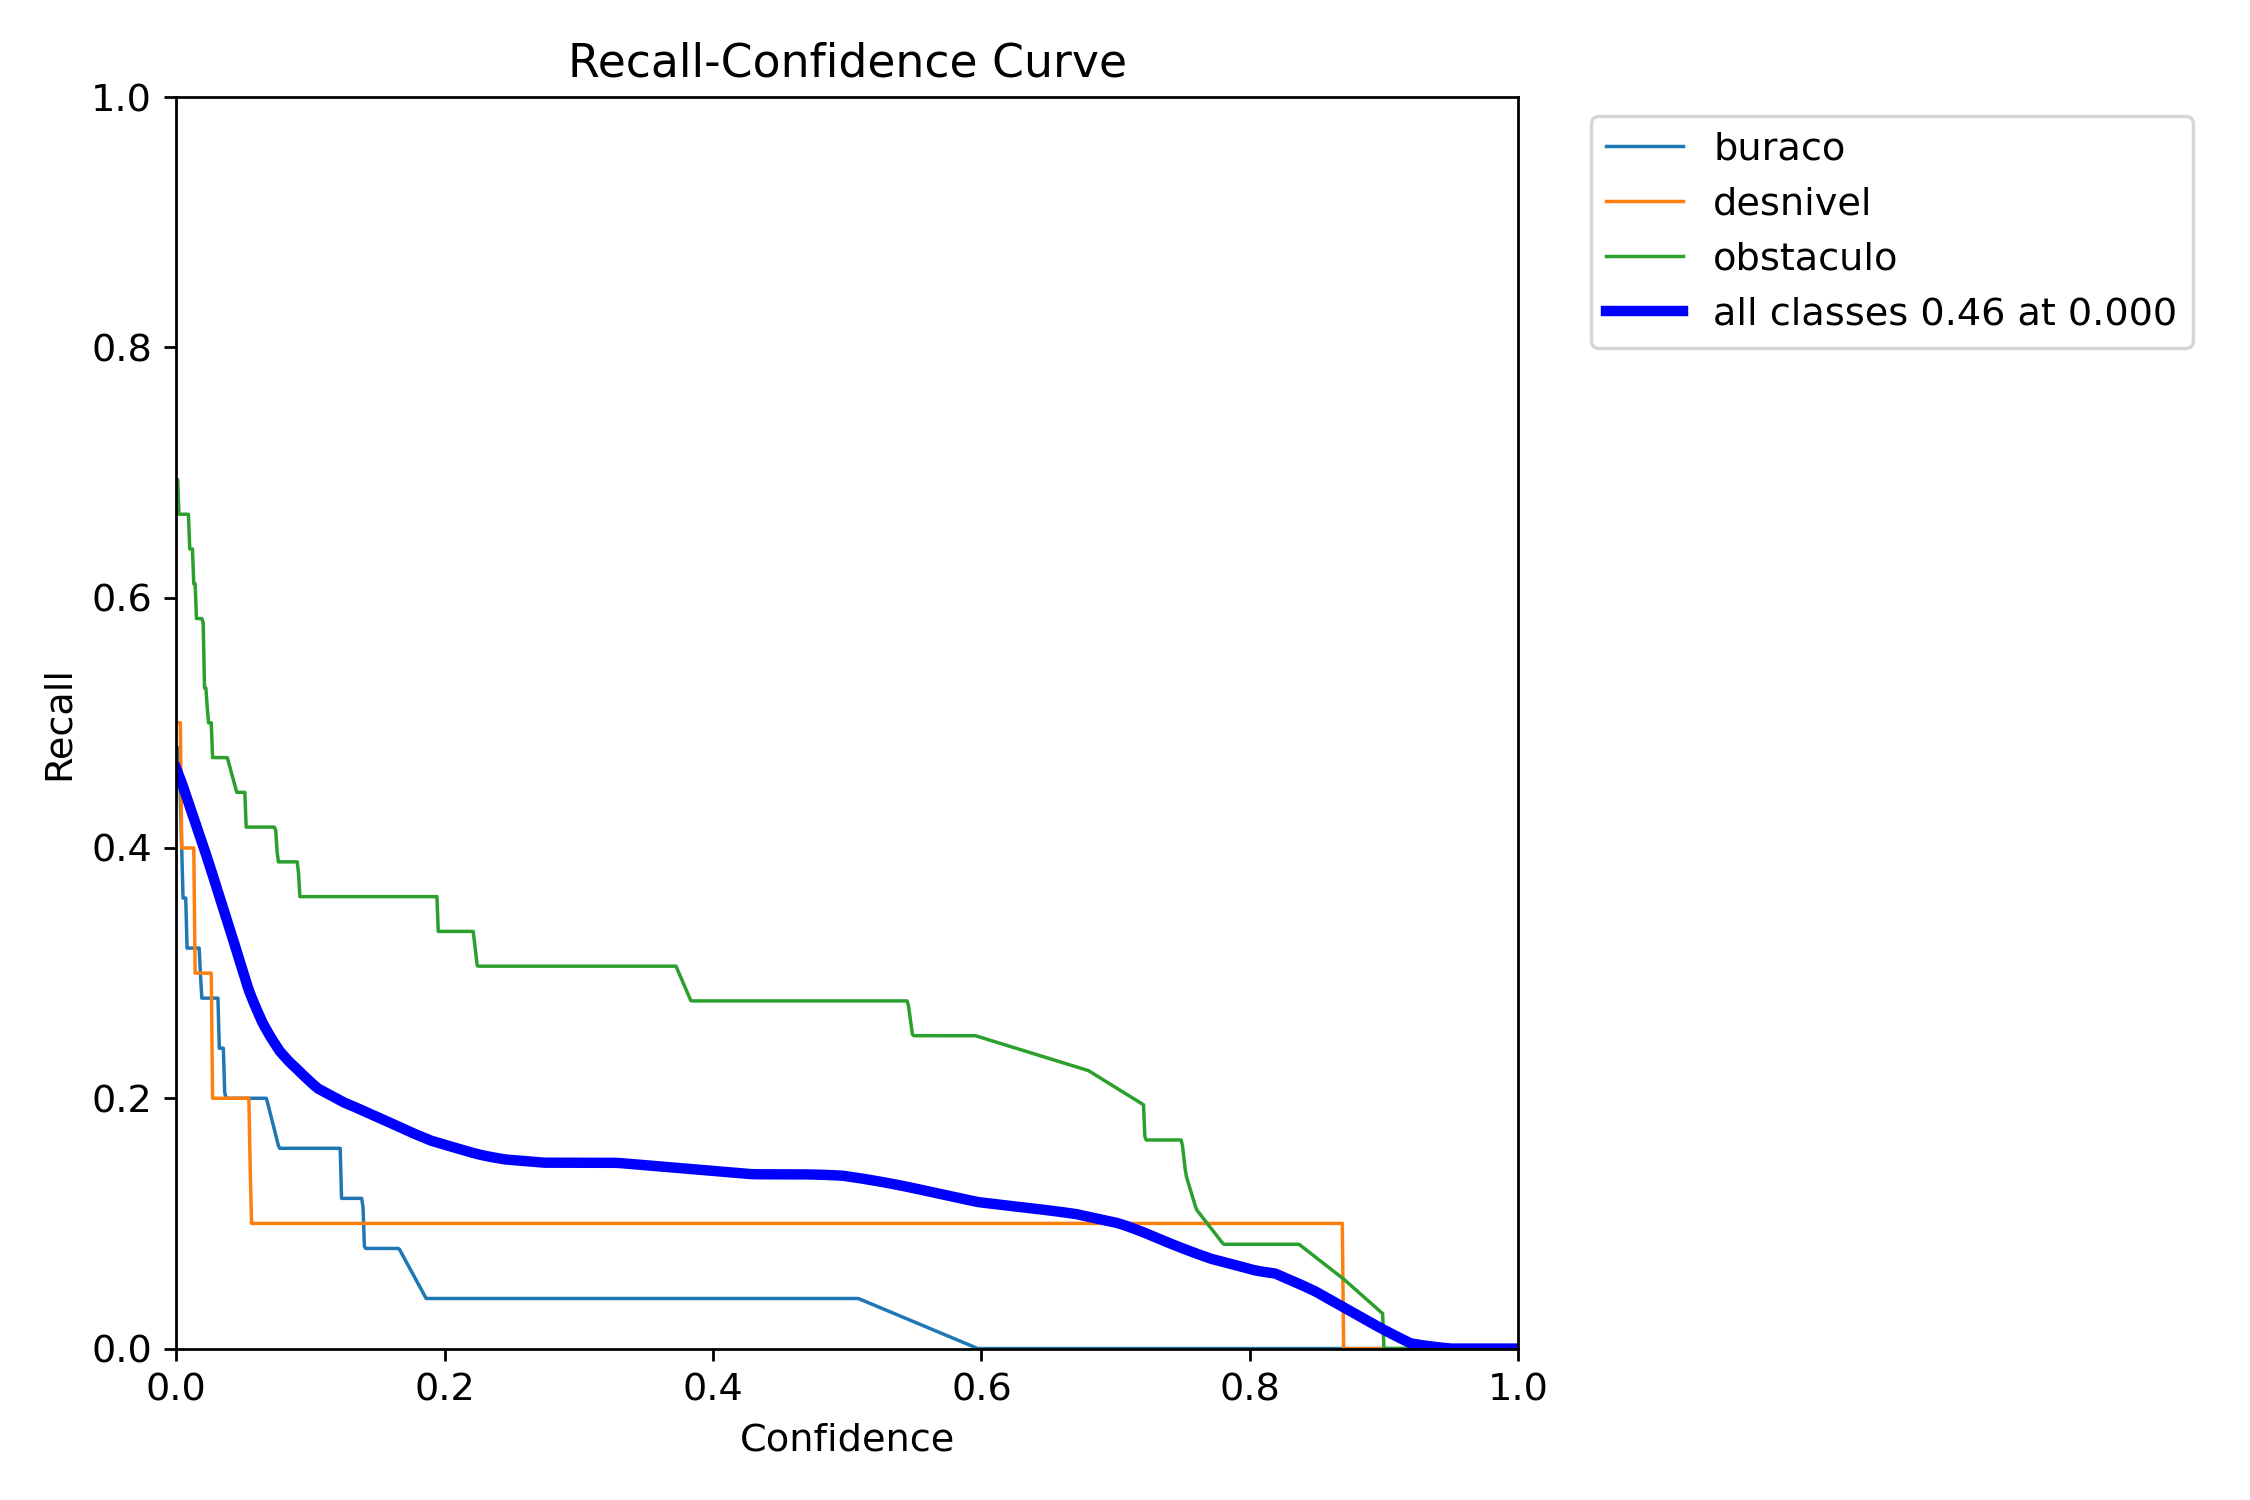

confusion_matrix.png


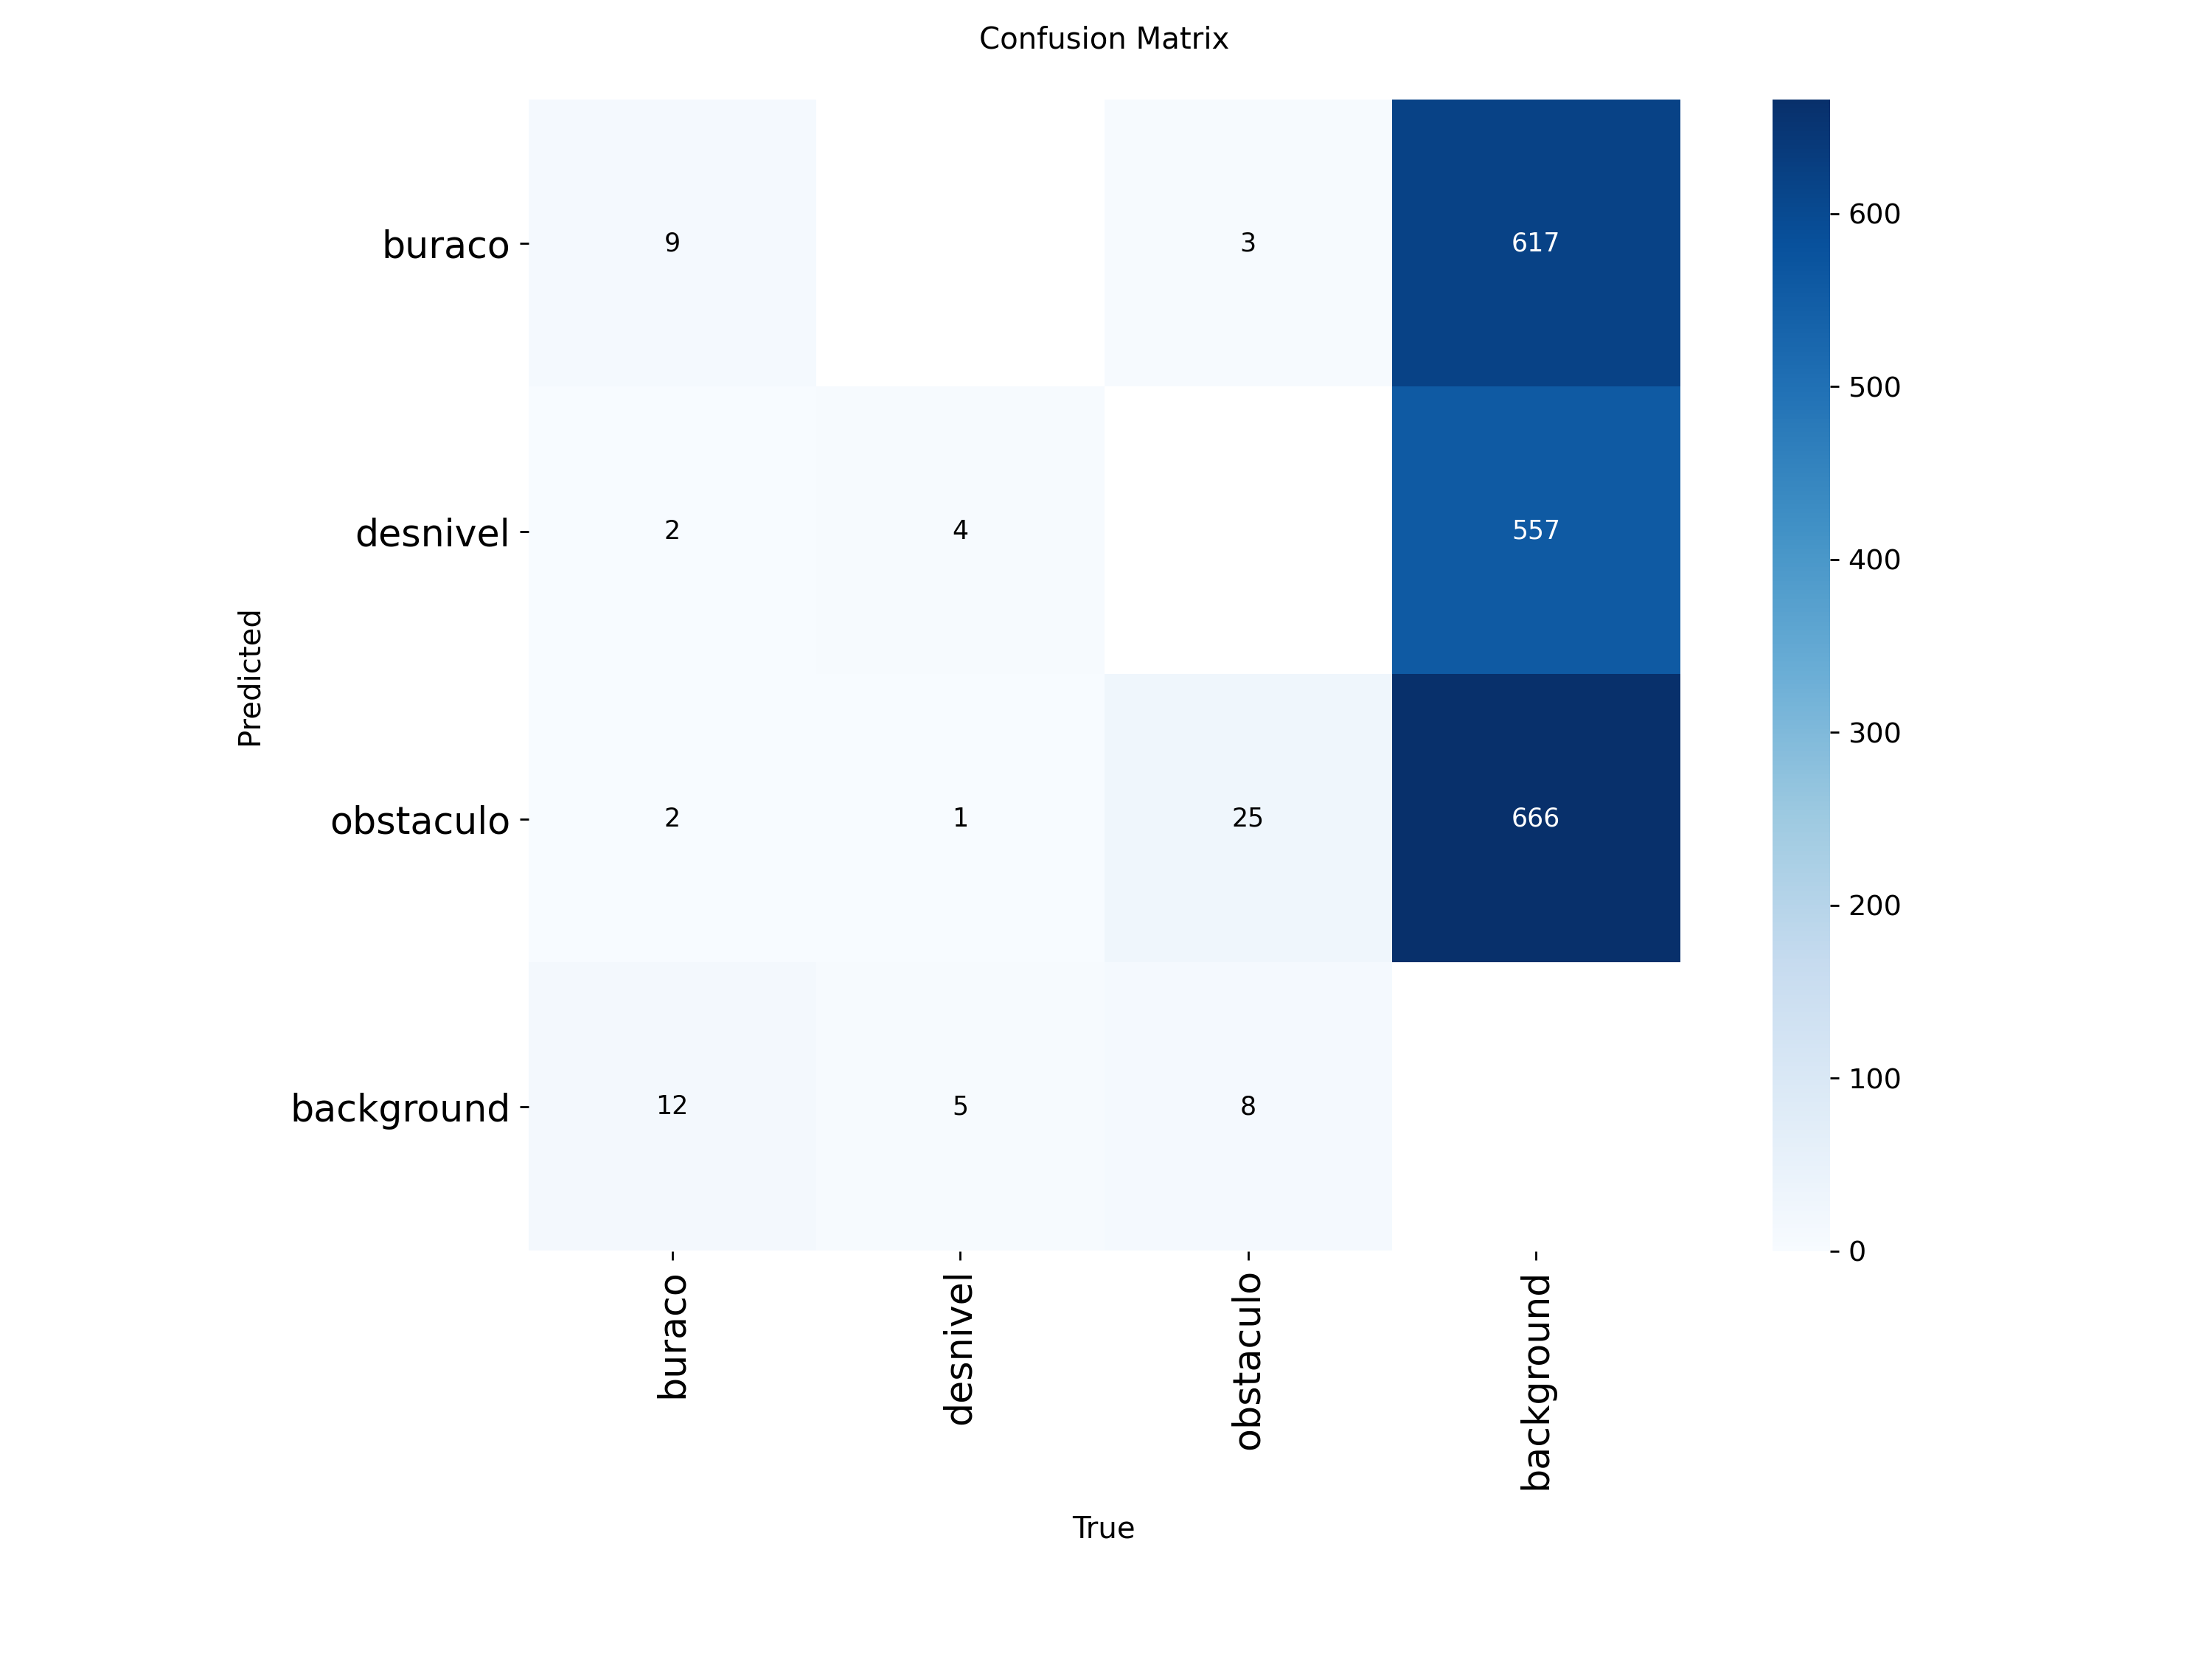

confusion_matrix_normalized.png


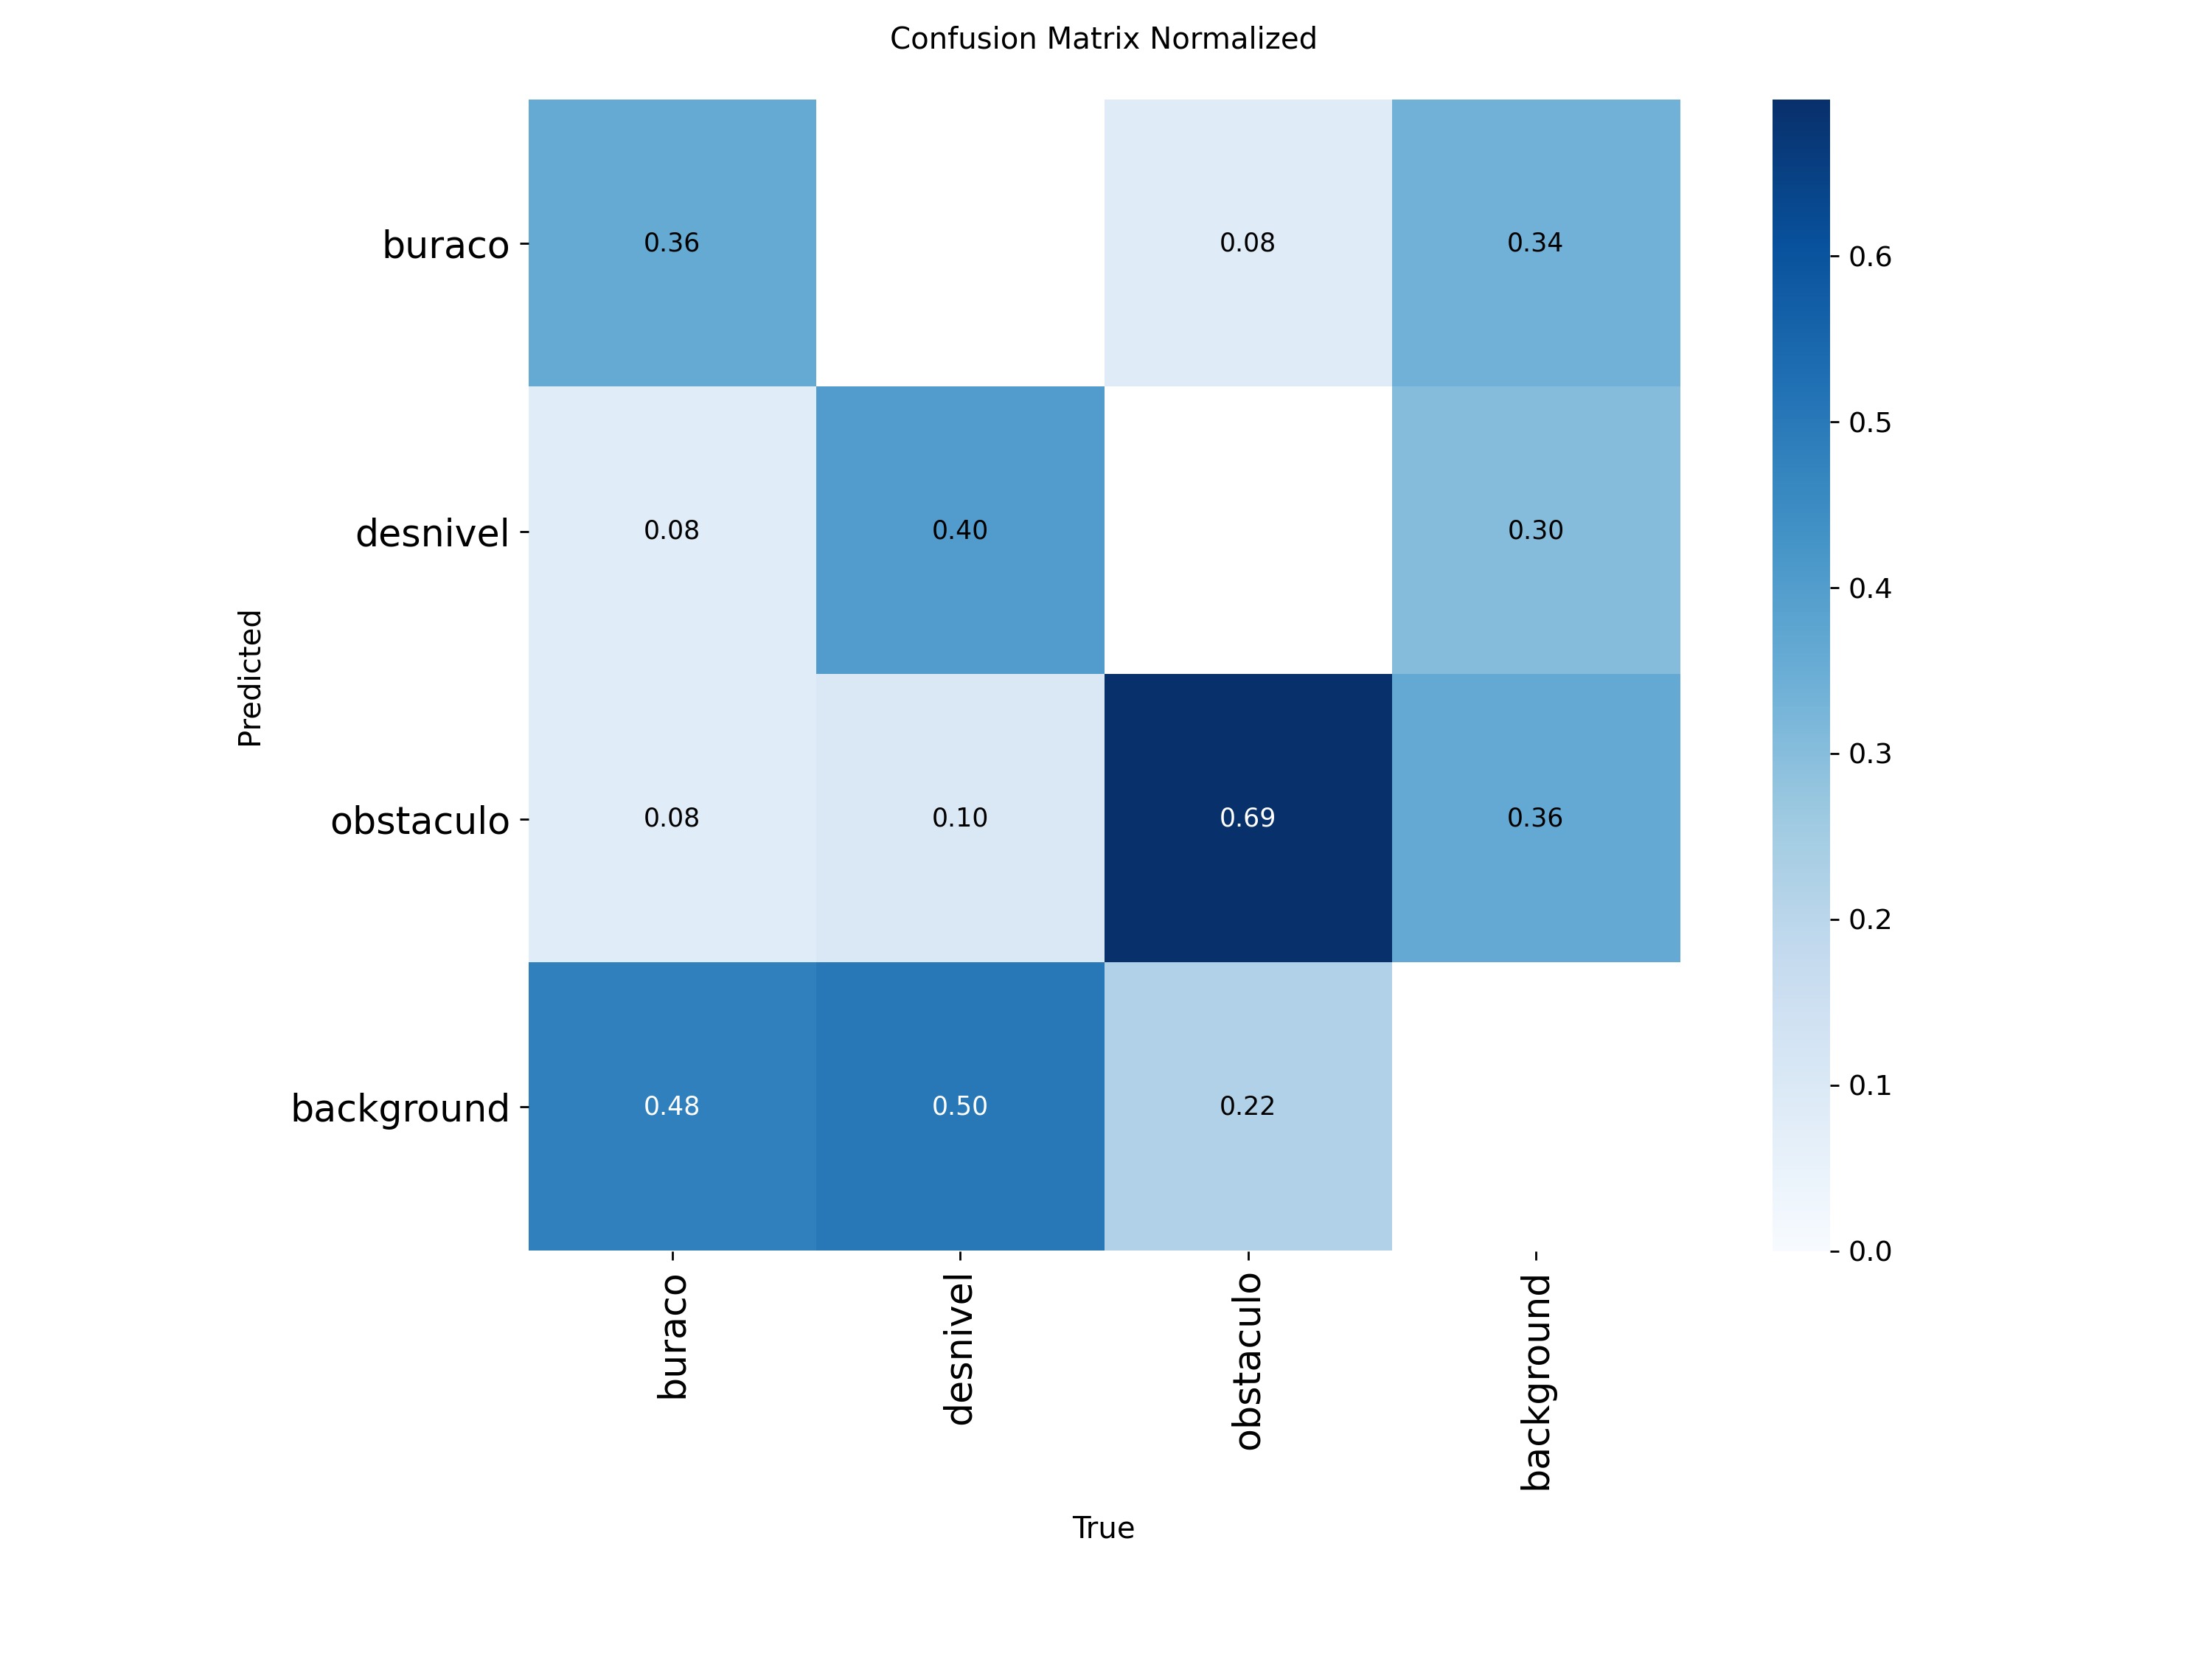

In [12]:
import glob
pasta_escolhido = "A_teste" if IMG == 640 else "A2_teste"
for f in sorted(glob.glob(f"/content/runs/{pasta_escolhido}/*.png")):   # matriz de confusão, curvas PR e F1
    print(Path(f).name)
    display(Image(f, width=700))

## 5. Experimento B — YOLO26s (comparação de tamanho)

Mesmo dataset, mesma resolução do modelo escolhido, modelo maior. Mostra no PDF a troca entre precisão e velocidade e justifica a escolha do nano para o tempo real.

In [13]:
YOLO("yolo26s.pt").train(name="B_yolo26s", imgsz=IMG, **comum)
B_BEST = "/content/runs/B_yolo26s/weights/best.pt"
tabelaB, geralB = avaliar(B_BEST, "B_teste", IMG)

comparacao = pd.DataFrame([{"modelo": "YOLO26n 640 (A)", **geralA}, {"modelo": "YOLO26n 960 (A2)", **geralA2},
                           {"modelo": f"YOLO26s {IMG} (B)", **geralB}]).round(3)
comparacao   # vai para o PDF

Ultralytics 8.4.214 🚀 Python-3.13.16 torch-2.14.1+cu130 CUDA:0 (Tesla T4, 14913MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=16, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/content/dataset/data.yaml, degrees=0.0, deterministic=True, device=, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=80, erasing=0.4, exist_ok=True, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=640, iou=None, kobj=1.0, line_width=None, lr0=0.01, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=yolo26s.pt, momentum=0.937, mosaic=1.0, multi_scale=0.0, name=B_yolo26s, nbs=64, nms=None, opset=None, optimize=False, optimi

,modelo,precisão,recall,mAP50,mAP50-95,ms por imagem (GPU T4)
0,YOLO26n 640 (A),0.476,0.139,0.159,0.082,7.348
1,YOLO26n 960 (A2),0.739,0.141,0.146,0.061,10.563
2,YOLO26s 640 (B),0.413,0.186,0.172,0.085,6.489


## 6. Desempenho por grupo de imagens (IA responsável)

O detector acerta igual em todo tipo de calçada? O grupo sai do nome do arquivo: `sp_<bairro>_<id>.jpg` vira o bairro (o Roboflow mantém esse começo do nome) e o resto entra como "dataset aberto". `REGIOES` junta bairros em regiões; bairro fora dela aparece com o próprio nome.

- **Teste** (só SP): compara os bairros ou regiões presentes. Se entrarem fotos da periferia, nomeie como `sp_periferia_<n>.jpg`.
- **Validação**: compara SP com o dataset aberto.

Grupos com menos de ~30 imagens dão números instáveis: diga isso no relatório.

In [14]:
import tempfile

REGIOES = {"se": "centro", "paulista": "centro", "itaquera": "periferia", "jabaquara": "periferia", "periferia": "periferia"}

def grupo_da_imagem(nome):
    partes = nome.lower().split("_")
    if partes[0] == "sp" and len(partes) > 2:
        return "SP: " + REGIOES.get(partes[1], partes[1])
    return "dataset aberto"

def avaliar_grupos(pesos, pasta_split, so_sp=False, imgsz=640):
    imagens = sorted((Path(dataset.location) / pasta_split / "images").glob("*"))
    separadas = {}
    for img in imagens:
        g = "SP (todas)" if so_sp and img.name.lower().startswith("sp_") else grupo_da_imagem(img.name)
        separadas.setdefault(g, []).append(img)
    modelo, linhas = YOLO(pesos), []
    for grupo, lista in sorted(separadas.items()):
        pasta = Path(tempfile.mkdtemp())
        (pasta / "lista.txt").write_text("\n".join(map(str, lista)))
        (pasta / "grupo.yaml").write_text(yaml.safe_dump(
            {"path": dataset.location, "train": str(pasta / "lista.txt"), "val": str(pasta / "lista.txt"), "names": cfg["names"]},
            allow_unicode=True))
        m = modelo.val(data=str(pasta / "grupo.yaml"), split="val", imgsz=imgsz, plots=False, verbose=False)
        linhas.append({"conjunto": pasta_split, "grupo": grupo, "imagens": len(lista), "precisão": m.box.mp,
                       "recall": m.box.mr, "mAP50": m.box.map50, "mAP50-95": m.box.map})
    return pd.DataFrame(linhas).round(3)

por_grupo = pd.concat([avaliar_grupos(MELHOR, PASTA_TESTE, imgsz=IMG),
                       avaliar_grupos(MELHOR, "valid", so_sp=True, imgsz=IMG)], ignore_index=True)
por_grupo   # vai para o PDF

Ultralytics 8.4.214 🚀 Python-3.13.16 torch-2.14.1+cu130 CUDA:0 (Tesla T4, 14913MiB)
YOLO26n summary (fused): 121 layers, 2,390,221 parameters, 0 gradients, 5.4 GFLOPs
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 2566.9±789.8 MB/s, size: 326.3 KB)
val: Scanning /content/dataset/test/labels.cache... 31 images, 5 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 31/31 6.8Mit/s 0.0s
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 2/2 2.4it/s 0.8s
                   all         31         71      0.476      0.139      0.159     0.0824
Speed: 1.0ms preprocess, 3.6ms inference, 0.0ms loss, 2.7ms postprocess per image
Ultralytics 8.4.214 🚀 Python-3.13.16 torch-2.14.1+cu130 CUDA:0 (Tesla T4, 14913MiB)
YOLO26n summary (fused): 121 layers, 2,390,221 parameters, 0 gradients, 5.4 GFLOPs
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 4281.9±1458.8 MB/s, size: 309.1 KB)
val: Scanning /content/dataset/valid/labels... 22 images, 1 backgrounds,

,conjunto,grupo,imagens,precisão,recall,mAP50,mAP50-95
0,test,SP: centro,31,0.476,0.139,0.159,0.082
1,valid,SP (todas),22,0.293,0.181,0.196,0.111
2,valid,dataset aberto,16,0.905,0.862,0.938,0.645


## 7. Exemplos de resultados e análise de erros

Compara, imagem a imagem do teste, as caixas anotadas (verde) com as previstas (vermelho). Acerto = mesma classe e IoU ≥ 0,5. Os piores casos alimentam a seção de limitações do PDF; os melhores viram as figuras de exemplo.

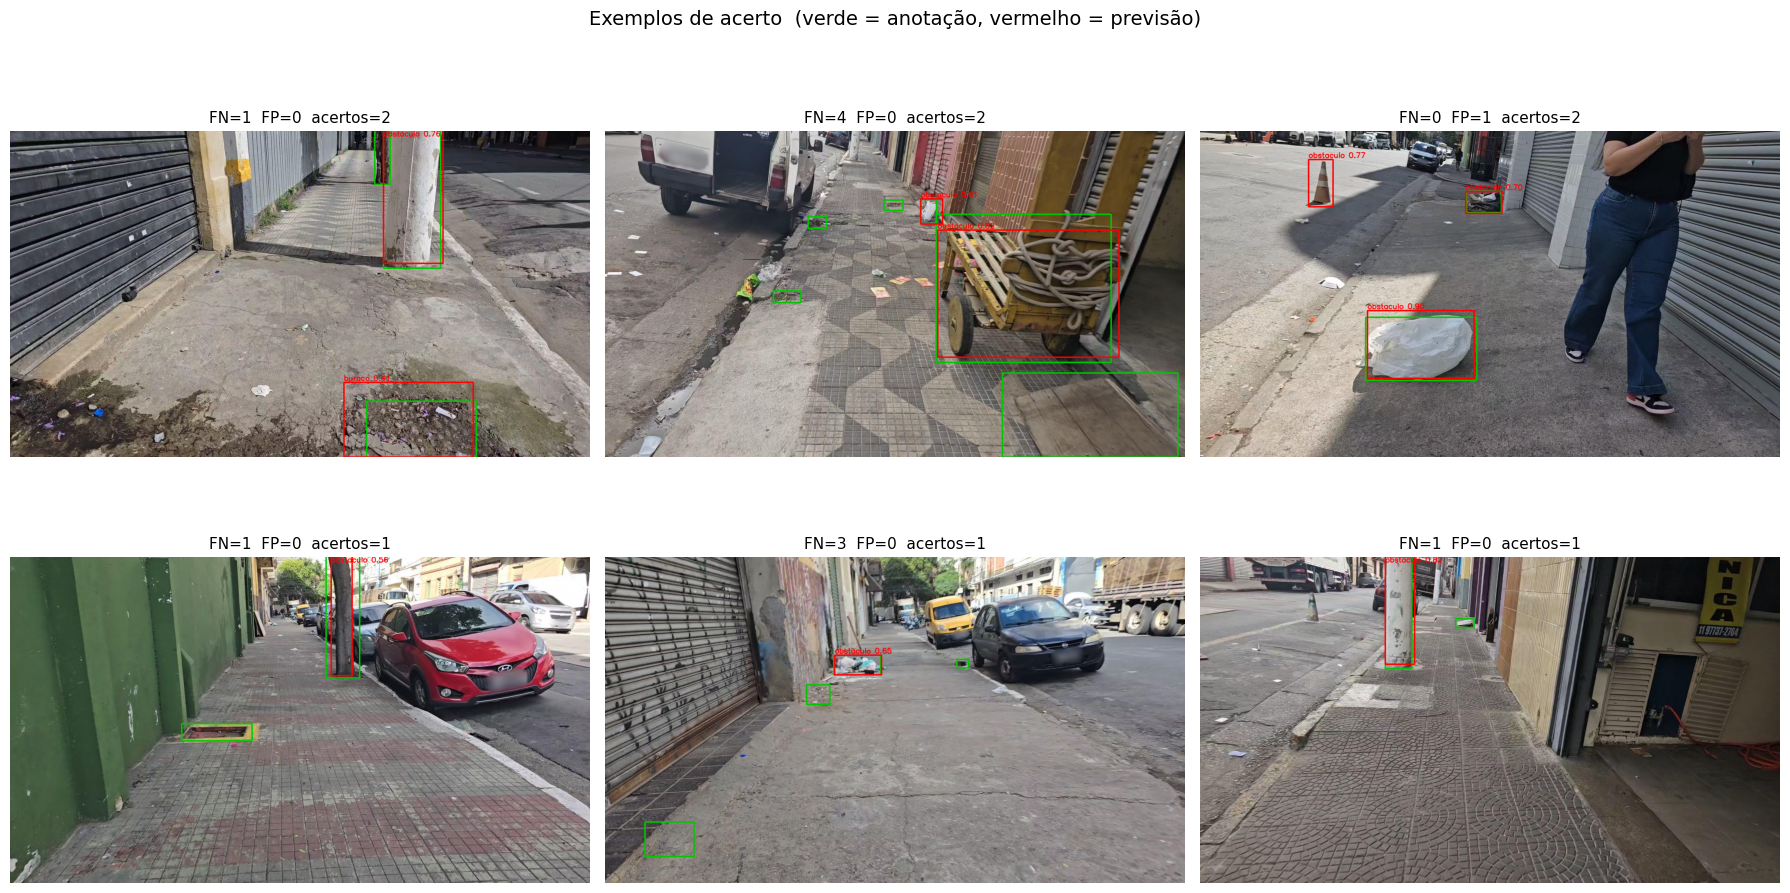

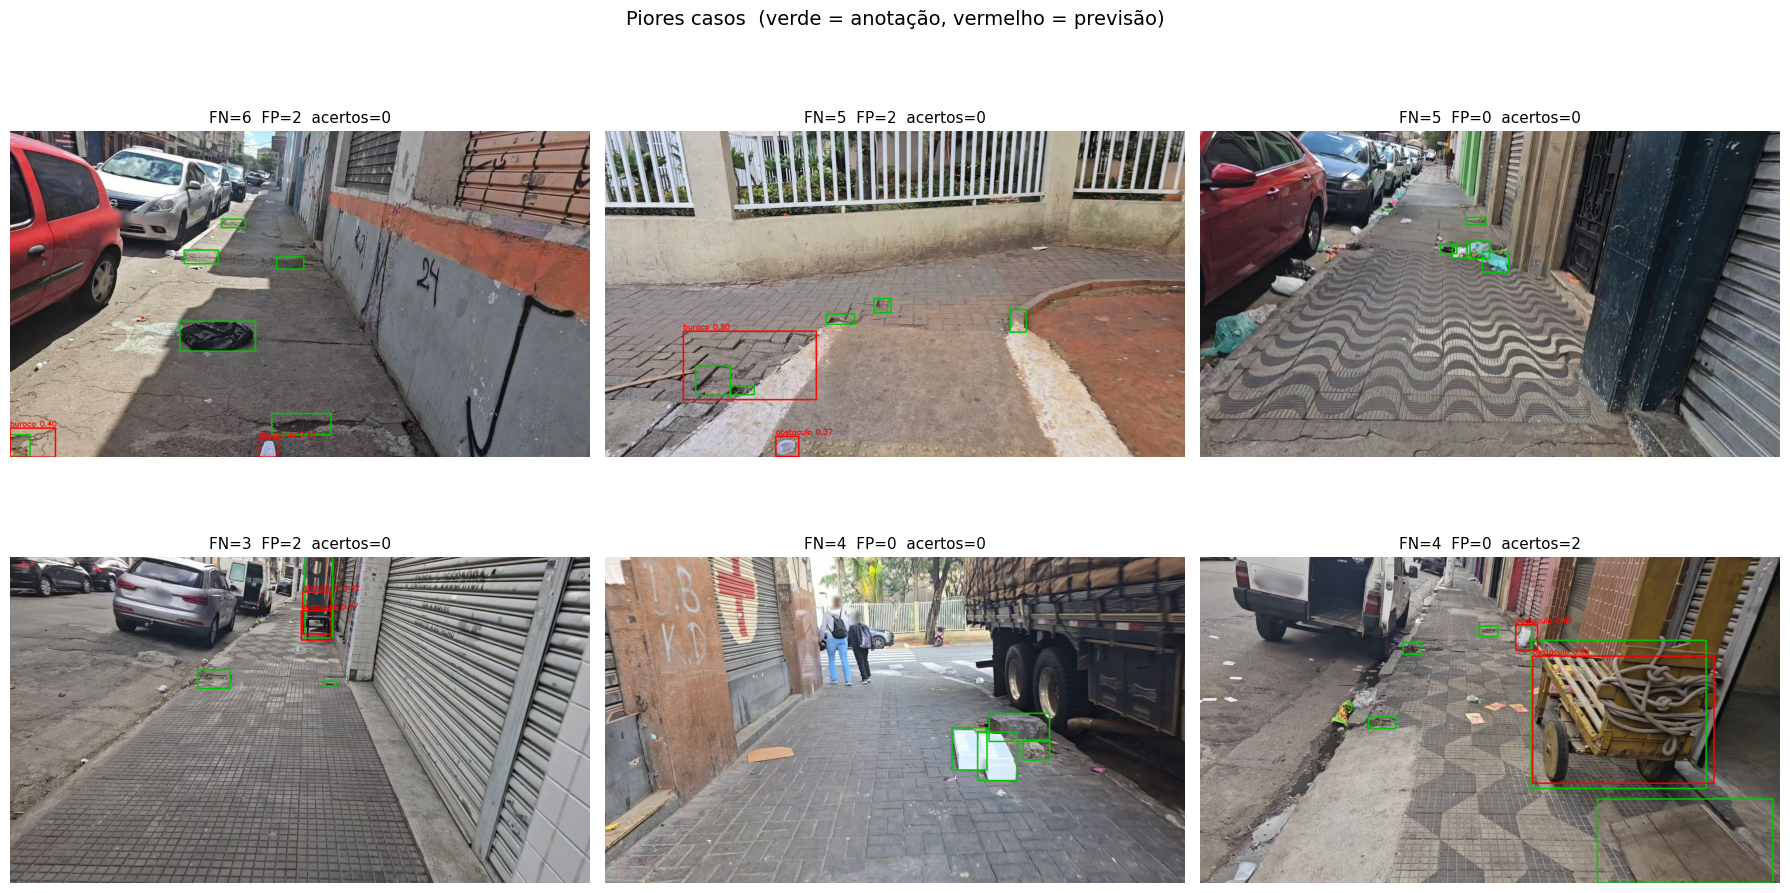

,0
anotadas,71
previstas,28
acertos,12
falsos negativos,59
falsos positivos,16


In [15]:
import cv2
import matplotlib.pyplot as plt

melhor = YOLO(MELHOR)
pasta_img = Path(dataset.location) / PASTA_TESTE / "images"
pasta_lbl = Path(dataset.location) / PASTA_TESTE / "labels"

def caixas_reais(img_path, w, h):
    f = pasta_lbl / (img_path.stem + ".txt")
    caixas = []
    if f.exists():
        for l in f.read_text().splitlines():
            if l.strip():
                c, xc, yc, bw, bh = map(float, l.split()[:5])
                caixas.append((int(c), (xc - bw / 2) * w, (yc - bh / 2) * h, (xc + bw / 2) * w, (yc + bh / 2) * h))
    return caixas

def iou(a, b):
    ix = max(0, min(a[2], b[2]) - max(a[0], b[0]))
    iy = max(0, min(a[3], b[3]) - max(a[1], b[1]))
    inter = ix * iy
    uniao = (a[2] - a[0]) * (a[3] - a[1]) + (b[2] - b[0]) * (b[3] - b[1]) - inter
    return inter / uniao if uniao > 0 else 0

casos = []
for p in sorted(pasta_img.glob("*")):
    r = melhor.predict(str(p), conf=0.35, imgsz=IMG, verbose=False)[0]
    h, w = r.orig_shape
    reais = caixas_reais(p, w, h)
    previstas = [(int(c), *xyxy) for xyxy, c in zip(r.boxes.xyxy.tolist(), r.boxes.cls.tolist())]
    usadas = set()
    for real in reais:
        for j, prev in enumerate(previstas):
            if j not in usadas and prev[0] == real[0] and iou(real[1:], prev[1:]) >= 0.5:
                usadas.add(j)
                break
    casos.append({"imagem": p.name, "anotadas": len(reais), "previstas": len(previstas), "acertos": len(usadas),
                  "falsos negativos": len(reais) - len(usadas), "falsos positivos": len(previstas) - len(usadas),
                  "_r": r, "_reais": reais})

def painel(lista, titulo, arquivo):
    fig, eixos = plt.subplots(2, 3, figsize=(18, 10))
    for ax in eixos.flat:
        ax.axis("off")
    for ax, caso in zip(eixos.flat, lista):
        img = caso["_r"].orig_img.copy()
        for c, x1, y1, x2, y2 in caso["_reais"]:
            cv2.rectangle(img, (int(x1), int(y1)), (int(x2), int(y2)), (0, 200, 0), 4)
        for xyxy, c, cf in zip(caso["_r"].boxes.xyxy.tolist(), caso["_r"].boxes.cls.tolist(), caso["_r"].boxes.conf.tolist()):
            x1, y1, x2, y2 = map(int, xyxy)
            cv2.rectangle(img, (x1, y1), (x2, y2), (0, 0, 255), 3)
            cv2.putText(img, f"{caso['_r'].names[int(c)]} {cf:.2f}", (x1, max(20, y1 - 6)), cv2.FONT_HERSHEY_SIMPLEX, 0.8, (0, 0, 255), 2)
        ax.imshow(cv2.cvtColor(img, cv2.COLOR_BGR2RGB))
        ax.set_title(f"FN={caso['falsos negativos']}  FP={caso['falsos positivos']}  acertos={caso['acertos']}", fontsize=11)
    fig.suptitle(titulo + "  (verde = anotação, vermelho = previsão)", fontsize=14)
    plt.tight_layout()
    plt.savefig(arquivo, dpi=110)
    plt.show()

bons = sorted(casos, key=lambda c: (c["acertos"], -c["falsos positivos"]), reverse=True)[:6]
piores = sorted(casos, key=lambda c: c["falsos negativos"] + c["falsos positivos"], reverse=True)[:6]
painel(bons, "Exemplos de acerto", "/content/runs/exemplos_acerto.png")
painel(piores, "Piores casos", "/content/runs/piores_casos.png")

resumo_erros = pd.DataFrame([{k: v for k, v in c.items() if not k.startswith("_")} for c in casos])
resumo_erros.sum(numeric_only=True)

Para o PDF, escolham **5 erros** dos piores casos e escrevam, para cada um: o que o modelo fez, a causa provável (sombra, folhas cobrindo o buraco, ângulo, classe confundida, anotação inconsistente) e a correção proposta.

## 8. Velocidade em CPU

O tempo real roda no notebook de vocês, sem GPU. Esta medida no CPU do Colab dá uma ideia; a medida que vai para o PDF sai do `src/tempo_real.py` rodando na máquina de vocês.

In [16]:
import time

amostra = sorted(pasta_img.glob("*"))[:30]
velocidade = []
for nome, pesos, tam in [("YOLO26n 640 (A)", A_BEST, 640), ("YOLO26n 960 (A2)", A2_BEST, 960)]:
    modelo_cpu = YOLO(pesos)
    modelo_cpu.predict(str(amostra[0]), device="cpu", imgsz=tam, verbose=False)   # aquecimento
    inicio = time.perf_counter()
    for p in amostra:
        modelo_cpu.predict(str(p), device="cpu", imgsz=tam, verbose=False)
    ms = (time.perf_counter() - inicio) / len(amostra) * 1000
    velocidade.append({"modelo": nome, "ms por imagem (CPU do Colab)": round(ms), "FPS aproximado": round(1000 / ms, 1)})
velocidade = pd.DataFrame(velocidade)
velocidade   # o FPS do PDF sai do tempo_real.py no notebook de vocês

,modelo,ms por imagem (CPU do Colab),FPS aproximado
0,YOLO26n 640 (A),90,11.1
1,YOLO26n 960 (A2),137,7.3


## 9. Baixar os resultados

Baixa dois arquivos para a pasta Downloads do computador:
- `best.pt`: o modelo escolhido na seção 4. Vai para a pasta `modelos/` do repositório (tem poucos MB e cabe no GitHub). Treinado em 960? Rodem o tempo real com `--imgsz 960`, ou `--imgsz 640` se ficar lento.
- `resultados_passo_firme.zip`: gráficos, matrizes de confusão, painéis de acertos e erros e as tabelas em CSV, para o PDF e a pasta `resultados/`.

Se o navegador perguntar se o Colab pode baixar vários arquivos, permitam.

In [17]:
import shutil
from google.colab import files

pasta_tabelas = Path("/content/runs/tabelas")
pasta_tabelas.mkdir(parents=True, exist_ok=True)
for nome, tabela in [("dataset", tabela_dataset), ("teste_por_classe_A_640", tabelaA), ("teste_por_classe_A2_960", tabelaA2),
                     ("resolucao_640_x_960", resolucao), ("comparacao_modelos", comparacao), ("por_grupo", por_grupo),
                     ("velocidade_cpu", velocidade)]:
    tabela.to_csv(pasta_tabelas / f"{nome}.csv", index=False)
(pasta_tabelas / "modelo_escolhido.txt").write_text(f"{ESCOLHIDO} | imgsz={IMG} | pesos={MELHOR}\n")

shutil.copy(MELHOR, "/content/best.pt")
shutil.make_archive("/content/resultados_passo_firme", "zip", "/content/runs")
files.download("/content/best.pt")
files.download("/content/resultados_passo_firme.zip")
print("Modelo escolhido:", ESCOLHIDO, "| imgsz:", IMG)

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

Modelo escolhido: A (640) | imgsz: 640


## O que deste notebook vai para o PDF

| Seção do PDF | O que levar |
| --- | --- |
| Metodologia | `tabela_dataset`, tabela de hiperparâmetros (seção 3), `results.png` |
| Resultados | `tabelaA` e `tabelaA2` (por classe), `resolucao` (640 × 960), `comparacao` (n × s), matriz de confusão normalizada, `exemplos_acerto.png` |
| Tempo real | `velocidade` (seção 8) e o FPS medido com o `tempo_real.py` |
| IA responsável | `por_grupo` (bairros/regiões no teste; SP × dataset aberto na validação) |
| Limitações | `piores_casos.png` e os 5 erros comentados |